#### 1. Initialization and Imports

Check every required dependency before starting expensive work, then import the libraries used throughout the notebook. The version report is saved with the final artifacts for reproducibility.

In [1]:
import importlib.util

required_packages = {
    "torch": "torch",
    "transformers": "transformers",
    "datasets": "datasets",
    "sklearn": "scikit-learn",
    "seqeval": "seqeval",
    "onnx": "onnx",
    "onnxruntime": "onnxruntime",
    "onnxscript": "onnxscript",
}
missing_packages = [
    package_name
    for import_name, package_name in required_packages.items()
    if importlib.util.find_spec(import_name) is None
]

if missing_packages:
    raise ImportError(
        "Missing required packages: "
        + ", ".join(missing_packages)
        + ". Install them with: python -m pip install -r requirements.txt"
    )

import gc
import json
import os
import platform
import random
import shutil
import sys
import time
from collections import Counter
from importlib.metadata import version as package_version
from pathlib import Path

import datasets
import matplotlib
import numpy as np
import onnx
import onnxruntime as ort
import onnxscript
import pandas as pd
import sklearn
import torch
import transformers
from datasets import load_dataset
from seqeval.metrics import (
    classification_report as seqeval_classification_report,
    f1_score as seqeval_f1_score,
    precision_score as seqeval_precision_score,
    recall_score as seqeval_recall_score,
)
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

environment_versions = {
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "cuda": torch.version.cuda,
    "transformers": transformers.__version__,
    "datasets": datasets.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "seqeval": package_version("seqeval"),
    "onnx": onnx.__version__,
    "onnxruntime": ort.__version__,
    "onnxscript": package_version("onnxscript"),
}

print("Device:", device)
print("Environment versions:")
for package_name, package_version_value in environment_versions.items():
    print(f"  {package_name}: {package_version_value}")

<REPO_ROOT>/.venv/Lib/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Environment versions:
  python: 3.11.9
  pytorch: 2.11.0+cu128
  cuda: 12.8
  transformers: 5.13.1
  datasets: 5.0.0
  numpy: 2.4.6
  scikit_learn: 1.9.0
  seqeval: 1.2.2
  onnx: 1.22.0
  onnxruntime: 1.27.0
  onnxscript: 0.7.1


#### 2. Hyperparameters

Keep experiment, AMP, DataLoader, checkpoint, artifact, and benchmark settings together. `EPOCHS` is the maximum; early stopping may finish training sooner. `RESUME_TRAINING` resumes only from the last fully completed epoch.

In [2]:
# Reproducibility
SEED = 42

# Dataset split and dynamic batching
VALIDATION_SIZE = 0.10
ORIGINAL_TRAIN_BATCH_SIZE = 16
TRAIN_BATCH_SIZE = 16
VALIDATION_BATCH_SIZE = 64
FINAL_TEST_BATCH_SIZE = 16
BATCH_SIZE = TRAIN_BATCH_SIZE  # Kept for later inference-only cells.
TOKENIZATION_BATCH_SIZE = 256
LENGTH_AUDIT_BATCH_SIZE = 1024
OVERFLOW_STRIDE = 128
PAD_TO_MULTIPLE_OF = 8
DATALOADER_NUM_WORKERS = 0
DATALOADER_PREFETCH_FACTOR = 2
PIN_MEMORY = False  # The local transfer probe was faster without pinning.
NON_BLOCKING_TRANSFERS = device.type == "cuda"

# Optional physical batch-size probe (training data only)
RUN_BATCH_SIZE_PROBE = False
TRAIN_BATCH_SIZE_CANDIDATES = (16, 32, 64)
VALIDATION_BATCH_SIZE_CANDIDATES = (16, 32, 64, 128)
BATCH_SIZE_PROBE_WARMUP_STEPS = 1
BATCH_SIZE_PROBE_TIMED_STEPS = 3
MIN_GPU_HEADROOM_FRACTION = 0.30  # Conservative guard above the 25% minimum.

# Training
EPOCHS = 25
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.01
EARLY_STOPPING_PATIENCE = 5
RESUME_TRAINING = True 
USE_MIXED_PRECISION = True
AMP_DTYPE = torch.float16
PROGRESS_UPDATE_INTERVAL = 20

# Loss
USE_WEIGHTED_LOSS = False
O_LABEL_WEIGHT = 1.0
PII_LABEL_WEIGHT = 2.0

# Learning-rate scheduler
USE_LR_SCHEDULER = True
LR_SCHEDULER_FACTOR = 0.5
LR_SCHEDULER_PATIENCE = 2
MIN_LEARNING_RATE = 1e-6

# Host-machine ONNX benchmark
ONNX_WARMUP_RUNS = 3
ONNX_BENCHMARK_REPETITIONS = 5
ONNX_BENCHMARK_BATCHES = 25

# One portable artifact root for every saved file
ARTIFACT_ROOT = Path("artifacts") / "tinybert_pii"
HUGGINGFACE_MODEL_DIRECTORY = ARTIFACT_ROOT / "huggingface_model"
TOKENIZER_DIRECTORY = ARTIFACT_ROOT / "tokenizer"
ONNX_MODEL_DIRECTORY = ARTIFACT_ROOT / "onnx_model"
METRICS_DIRECTORY = ARTIFACT_ROOT / "metrics"
CONFIG_DIRECTORY = ARTIFACT_ROOT / "config"
CHECKPOINT_DIRECTORY = ARTIFACT_ROOT / "checkpoints"

for directory in [
    HUGGINGFACE_MODEL_DIRECTORY,
    TOKENIZER_DIRECTORY,
    ONNX_MODEL_DIRECTORY,
    METRICS_DIRECTORY,
    CONFIG_DIRECTORY,
    CHECKPOINT_DIRECTORY,
]:
    directory.mkdir(parents=True, exist_ok=True)

LATEST_CHECKPOINT_PATH = CHECKPOINT_DIRECTORY / "latest_checkpoint.pt"
BEST_CHECKPOINT_PATH = CHECKPOINT_DIRECTORY / "best_checkpoint.pt"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

amp_enabled = USE_MIXED_PRECISION and device.type == "cuda"
gpu_name = torch.cuda.get_device_name(0) if device.type == "cuda" else "None"
if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
tf32_matmul_enabled = (
    torch.backends.cuda.matmul.allow_tf32 if device.type == "cuda" else False
)
tf32_cudnn_enabled = (
    torch.backends.cudnn.allow_tf32 if device.type == "cuda" else False
)

print(f"Reproducibility seed: {SEED}")
print("Selected device:", device)
print("GPU name:", gpu_name)
print("AMP enabled:", amp_enabled)
print("AMP datatype:", AMP_DTYPE)
print("GradScaler enabled:", scaler.is_enabled())
print("TF32 matmul enabled:", tf32_matmul_enabled)
print("TF32 cuDNN enabled:", tf32_cudnn_enabled)
print("Resolved artifact root:", ARTIFACT_ROOT.resolve())

Reproducibility seed: 42
Selected device: cuda
GPU name: NVIDIA GeForce RTX 4050 Laptop GPU
AMP enabled: True
AMP datatype: torch.float16
GradScaler enabled: True
TF32 matmul enabled: True
TF32 cuDNN enabled: True
Resolved artifact root: <REPO_ROOT>/model/TinyBERT-4/artifacts/tinybert_pii


#### 3. Dataset and Model Configuration

Pin the exact dataset and TinyBERT revisions observed during this notebook repair. These revisions make later `Run All` executions independent of changes to each repository's `main` branch.

In [3]:
DATASET_NAME = "ai4privacy/pii-masking-openpii-1.5m"
DATASET_REVISION = "a785eb528e28be2693c3718a27e066970de5dadb"

MODEL_NAME = "huawei-noah/TinyBERT_General_4L_312D"
MODEL_REVISION = "34707a33cd59a94ecde241ac209bf35103691b43"

print(f"Dataset: {DATASET_NAME} @ {DATASET_REVISION}")
print(f"Model:   {MODEL_NAME} @ {MODEL_REVISION}")

Dataset: ai4privacy/pii-masking-openpii-1.5m @ a785eb528e28be2693c3718a27e066970de5dadb
Model:   huawei-noah/TinyBERT_General_4L_312D @ 34707a33cd59a94ecde241ac209bf35103691b43


#### 4. Load Dataset

Load the pinned Hugging Face dataset and record the fingerprint of each untouched official split.

In [4]:
dataset = load_dataset(
    DATASET_NAME,
    revision=DATASET_REVISION,
)

print(f"Dataset name: {DATASET_NAME}")
print(f"Dataset revision: {DATASET_REVISION}")
print("Official split fingerprints:")
for split_name, split_data in dataset.items():
    print(f"  {split_name}: {split_data._fingerprint}")

dataset

Dataset name: ai4privacy/pii-masking-openpii-1.5m
Dataset revision: a785eb528e28be2693c3718a27e066970de5dadb
Official split fingerprints:
  train: 454de69c898afa05
  validation: b88484396f17b6c4


DatasetDict({
    train: Dataset({
        features: ['source_text', 'masked_text', 'privacy_mask', 'split', 'uid', 'language', 'region', 'script', 'mbert_tokens', 'mbert_token_classes', 'source_dataset'],
        num_rows: 1309912
    })
    validation: Dataset({
        features: ['source_text', 'masked_text', 'privacy_mask', 'split', 'uid', 'language', 'region', 'script', 'mbert_tokens', 'mbert_token_classes', 'source_dataset'],
        num_rows: 326463
    })
})

#### 5. Dataset Citation and License

This notebook uses the **OpenPII 1.5M: Multilingual PII Masking Dataset with Asia Pacific Extension**, published by **Ai4Privacy / Ai Suisse SA** on Hugging Face.

The dataset contains synthetic personally identifiable information (PII) and is released under the **CC BY 4.0** license. It may be used for research, commercial use, redistribution, and modification, provided appropriate attribution is given.

**Dataset:** `ai4privacy/pii-masking-openpii-1.5m`  
**Publisher:** Ai4Privacy / Ai Suisse SA  
**License:** CC BY 4.0  
**Year:** 2026  
**Source:** https://huggingface.co/datasets/ai4privacy/pii-masking-openpii-1.5m

##### BibTeX

```bibtex
@dataset{ai4privacy_openpii_1_5m_2026,
  author = {Ai4Privacy},
  title = {OpenPII 1.5M: Multilingual PII Masking Dataset with Asia Pacific Extension},
  year = {2026},
  publisher = {Hugging Face},
  url = {https://huggingface.co/datasets/ai4privacy/pii-masking-openpii-1.5m}
}
```


#### 6. Filter English Data

Filter every original split using only `language == "en"`. No broad cleaning rule is applied, so English rows with an empty `privacy_mask` remain part of the experiment.

In [5]:
english_dataset = dataset.filter(
    lambda example: example["language"] == "en"
)

print("Original dataset:")
for split_name, split_data in dataset.items():
    print(f"  {split_name}: {len(split_data):,}")

print()
print("English-only dataset:")
for split_name, split_data in english_dataset.items():
    print(
        f"  {split_name}: {len(split_data):,} rows | "
        f"fingerprint={split_data._fingerprint}"
    )

Original dataset:
  train: 1,309,912
  validation: 326,463

English-only dataset:
  train: 163,740 rows | fingerprint=6f5a2d717f5534c2
  validation: 40,909 rows | fingerprint=6df14acc1c402377


#### 7. Show Five Random Examples

Display source text beside the dataset's expected masked text. `SystemRandom` keeps this display-only sampling independent of every deterministic training seed, so rerunning only this cell shows different examples without changing the split or training order.

In [6]:
sample_size = min(5, len(english_dataset["train"]))
sample_indices = random.SystemRandom().sample(
    range(len(english_dataset["train"])),
    k=sample_size,
)
random_examples = english_dataset["train"].select(sample_indices)

examples_df = pd.DataFrame({
    "Source text": random_examples["source_text"],
    "Masked text": random_examples["masked_text"],
})

pd.set_option("display.max_colwidth", None)
examples_df

,Source text,Masked text
0,"We appreciate your commitment to cultural diversity; remember, respectful dialogue transcends any F or 9339294206 differences.","We appreciate your commitment to cultural diversity; remember, respectful dialogue transcends any [SEX_1] or [SOCIALNUM_1] differences."
1,"Dear Mrs Melrose Nissaf Botros, welcome to our premium trading platform; to complete your onboarding, please provide your S@gmail.com, 00491.523747 and upload a copy of your 741638416553 before July 26th, 1970.","Dear [TITLE_1] [GIVENNAME_1] [SURNAME_1], welcome to our premium trading platform; to complete your onboarding, please provide your [EMAIL_1], [TELEPHONENUM_1] and upload a copy of your [IDCARDNUM_1] before [DATE_1]."
2,"Our new interactive exhibit invites Flor Kolodynska to co‑curate stories about their hometown, sharing memories via the digital board.","Our new interactive exhibit invites [GIVENNAME_1] [SURNAME_1] to co‑curate stories about their hometown, sharing memories via the digital board."
3,"The Ancient Rome package costs $2,499; kindly enter your 6293685220255031 on our secure portal or call +1254532 9826 for assistance.","The Ancient Rome package costs $2,499; kindly enter your [CREDITCARDNUMBER_1] on our secure portal or call [TELEPHONENUM_1] for assistance."
4,"From: Mr Avigail Sabiene Askandar <puniyakupoglu@aol.com>\nTo: Mister Community Members\nSubject: You're Invited – Local Oral Storytelling Night on March 20th, 2019\n\nDear Neighbour,\nWe are delighted to invite you to our upcoming Local Oral Storytelling Night at the community hall, located at 342A Watten View, Singapore Ang Mo Kio 31 788448. Bring your favourite tale, or simply come to enjoy the rich tapestry of voices.\nPlease RSVP by replying to this email or calling +657-871.541.4131.\nWarm regards,\nMr Natthaphon Caburet","From: [TITLE_3] [GIVENNAME_2] [SURNAME_2] <[EMAIL_1]>\nTo: [TITLE_2] Community Members\nSubject: You're Invited – Local Oral Storytelling Night on [DATE_1]\n\nDear Neighbour,\nWe are delighted to invite you to our upcoming Local Oral Storytelling Night at the community hall, located at [BUILDINGNUM_1] [STREET_1], [CITY_1] [ZIPCODE_1]. Bring your favourite tale, or simply come to enjoy the rich tapestry of voices.\nPlease RSVP by replying to this email or calling [TELEPHONENUM_1].\nWarm regards,\n[TITLE_1] [GIVENNAME_1] [SURNAME_1]"


#### 8. Create Train, Validation, and Final Test Splits

Create the deterministic multilabel-aware project train/validation split only from the official English training rows. Keep the untouched official English validation split separately, detect every entity type unsupported by training, and exclude only affected rows from scored final-test evaluation.

In [7]:
def extract_entity_types(privacy_mask, row_identifier):
    if not isinstance(privacy_mask, list):
        raise ValueError(f"{row_identifier} has a privacy_mask that is not a list.")

    row_entity_types = set()

    for span_index, span in enumerate(privacy_mask):
        if not isinstance(span, dict):
            raise ValueError(
                f"{row_identifier}, span {span_index} is not a dictionary."
            )

        entity_type = span.get("label")
        if not isinstance(entity_type, str) or not entity_type:
            raise ValueError(
                f"{row_identifier}, span {span_index} has no valid label."
            )

        row_entity_types.add(entity_type)

    return frozenset(row_entity_types)


official_training_dataset = english_dataset["train"]
original_final_test_dataset = english_dataset["validation"]

official_training_row_entity_types = [
    extract_entity_types(privacy_mask, f"Official training row {row_index}")
    for row_index, privacy_mask in enumerate(
        official_training_dataset["privacy_mask"]
    )
]
official_training_entity_types = sorted(
    {
        entity_type
        for row_entity_types in official_training_row_entity_types
        for entity_type in row_entity_types
    }
)
entity_type_to_column = {
    entity_type: column_index
    for column_index, entity_type in enumerate(official_training_entity_types)
}

multilabel_indicator = np.zeros(
    (len(official_training_dataset), len(official_training_entity_types)),
    dtype=np.uint8,
)
row_label_indices = []

for row_index, row_entity_types in enumerate(official_training_row_entity_types):
    label_indices = tuple(
        entity_type_to_column[entity_type]
        for entity_type in sorted(row_entity_types)
    )
    row_label_indices.append(label_indices)

    if label_indices:
        multilabel_indicator[row_index, list(label_indices)] = 1


def deterministic_multilabel_split(
    indicator,
    labels_by_row,
    validation_fraction,
    seed,
):
    row_count, label_count = indicator.shape
    validation_row_count = int(np.ceil(row_count * validation_fraction))
    training_row_count = row_count - validation_row_count
    label_support = indicator.sum(axis=0).astype(int)

    if np.any(label_support == 0):
        raise ValueError("The multilabel indicator contains an empty label column.")

    rng = np.random.default_rng(seed)
    tie_order = rng.permutation(row_count)
    tie_rank = np.empty(row_count, dtype=np.int64)
    tie_rank[tie_order] = np.arange(row_count)
    split_priority_order = rng.permutation(2)
    split_priority = np.empty(2, dtype=np.int64)
    split_priority[split_priority_order] = np.arange(2)

    assignments = np.full(row_count, -1, dtype=np.int8)
    remaining_split_rows = np.array(
        [training_row_count, validation_row_count],
        dtype=float,
    )
    remaining_label_targets = np.outer(
        remaining_split_rows / row_count,
        label_support.astype(float),
    )
    remaining_label_support = label_support.copy()
    rows_by_label = [
        np.flatnonzero(indicator[:, label_index])
        for label_index in range(label_count)
    ]

    def assign_row(row_index, split_index):
        assignments[row_index] = split_index
        remaining_split_rows[split_index] -= 1

        for label_index in labels_by_row[row_index]:
            remaining_label_targets[split_index, label_index] -= 1
            remaining_label_support[label_index] -= 1

    # Preserve empty-mask rows with the same deterministic split ratio.
    empty_mask_indices = np.array(
        [
            row_index
            for row_index, label_indices in enumerate(labels_by_row)
            if not label_indices
        ],
        dtype=np.int64,
    )
    empty_mask_indices = np.array(
        sorted(empty_mask_indices, key=lambda row_index: tie_rank[row_index]),
        dtype=np.int64,
    )
    validation_empty_count = int(
        np.ceil(len(empty_mask_indices) * validation_fraction)
    )
    validation_empty_indices = set(
        empty_mask_indices[:validation_empty_count].tolist()
    )

    for row_index in empty_mask_indices:
        split_index = 1 if row_index in validation_empty_indices else 0
        assign_row(int(row_index), split_index)

    # Reserve deterministic training anchors, processing rare labels first.
    uncovered_labels = set(range(label_count))
    training_anchor_indices = []

    while uncovered_labels:
        rarest_label = min(
            uncovered_labels,
            key=lambda label_index: (label_support[label_index], label_index),
        )
        candidates = [
            int(row_index)
            for row_index in rows_by_label[rarest_label]
            if assignments[row_index] == -1
        ]

        anchor_index = max(
            candidates,
            key=lambda row_index: (
                sum(
                    1.0 / label_support[label_index]
                    for label_index in labels_by_row[row_index]
                    if label_index in uncovered_labels
                ),
                -tie_rank[row_index],
            ),
        )
        assign_row(anchor_index, split_index=0)
        training_anchor_indices.append(anchor_index)
        uncovered_labels.difference_update(labels_by_row[anchor_index])

    # Iteratively assign rows carrying the rarest remaining label.
    while np.any(remaining_label_support > 0):
        active_labels = np.flatnonzero(remaining_label_support > 0)
        rarest_label = min(
            active_labels,
            key=lambda label_index: (
                remaining_label_support[label_index],
                label_support[label_index],
                label_index,
            ),
        )
        candidates = [
            int(row_index)
            for row_index in rows_by_label[rarest_label]
            if assignments[row_index] == -1
        ]
        candidates.sort(key=lambda row_index: tie_rank[row_index])

        for row_index in candidates:
            eligible_splits = np.flatnonzero(remaining_split_rows > 0)
            split_index = max(
                eligible_splits,
                key=lambda candidate_split: (
                    remaining_label_targets[candidate_split, rarest_label],
                    remaining_split_rows[candidate_split],
                    -split_priority[candidate_split],
                ),
            )
            assign_row(row_index, int(split_index))

    # This fallback should be empty, but it protects complete row coverage.
    unassigned_rows = np.flatnonzero(assignments == -1)
    unassigned_rows = sorted(unassigned_rows, key=lambda row_index: tie_rank[row_index])

    for row_index in unassigned_rows:
        eligible_splits = np.flatnonzero(remaining_split_rows > 0)
        split_index = max(
            eligible_splits,
            key=lambda candidate_split: (
                remaining_split_rows[candidate_split],
                -split_priority[candidate_split],
            ),
        )
        assign_row(int(row_index), int(split_index))

    if np.any(assignments == -1) or np.any(remaining_split_rows != 0):
        raise RuntimeError("The multilabel split did not assign every row exactly once.")

    training_indices = np.flatnonzero(assignments == 0)
    validation_indices = np.flatnonzero(assignments == 1)

    return (
        training_indices,
        validation_indices,
        np.asarray(training_anchor_indices, dtype=np.int64),
        label_support,
    )


In [8]:
(
    project_train_indices,
    project_validation_indices,
    training_anchor_indices,
    official_training_label_row_support,
) = deterministic_multilabel_split(
    multilabel_indicator,
    row_label_indices,
    validation_fraction=VALIDATION_SIZE,
    seed=SEED,
)

project_train_dataset = official_training_dataset.select(project_train_indices)
project_validation_dataset = official_training_dataset.select(
    project_validation_indices
)

original_final_test_entity_types = set()
unsupported_final_test_row_indices = []
unsupported_final_test_span_counts = Counter()

for row_index, privacy_mask in enumerate(
    original_final_test_dataset["privacy_mask"]
):
    row_entity_types = extract_entity_types(
        privacy_mask,
        f"Original final-test row {row_index}",
    )
    original_final_test_entity_types.update(row_entity_types)

unsupported_final_test_types = (
    original_final_test_entity_types - set(official_training_entity_types)
)

for row_index, privacy_mask in enumerate(
    original_final_test_dataset["privacy_mask"]
):
    unsupported_spans = [
        span
        for span in privacy_mask
        if span["label"] in unsupported_final_test_types
    ]
    if unsupported_spans:
        unsupported_final_test_row_indices.append(row_index)
        unsupported_final_test_span_counts.update(
            span["label"] for span in unsupported_spans
        )

unsupported_final_test_row_index_set = set(
    unsupported_final_test_row_indices
)
scored_final_test_source_indices = [
    row_index
    for row_index in range(len(original_final_test_dataset))
    if row_index not in unsupported_final_test_row_index_set
]
scored_final_test_dataset = original_final_test_dataset.select(
    scored_final_test_source_indices
)

print("Unsupported official final-test entity types:", sorted(unsupported_final_test_types))
print(f"Affected final-test rows: {len(unsupported_final_test_row_indices):,}")
print(f"Affected final-test spans: {sum(unsupported_final_test_span_counts.values()):,}")
for entity_type in sorted(unsupported_final_test_span_counts):
    print(
        f"  {entity_type}: "
        f"{unsupported_final_test_span_counts[entity_type]:,} spans"
    )

Unsupported official final-test entity types: ['HEIGHT']
Affected final-test rows: 1
Affected final-test spans: 1
  HEIGHT: 1 spans


In [9]:
def summarize_entity_annotations(split_name, split_dataset):
    entity_row_counts = Counter()
    entity_span_counts = Counter()
    empty_mask_rows = 0

    for row_index, privacy_mask in enumerate(split_dataset["privacy_mask"]):
        row_entity_types = extract_entity_types(
            privacy_mask,
            f"{split_name} row {row_index}",
        )
        entity_row_counts.update(row_entity_types)
        entity_span_counts.update(span["label"] for span in privacy_mask)
        empty_mask_rows += int(not privacy_mask)

    return entity_row_counts, entity_span_counts, empty_mask_rows


train_row_counts, train_span_counts, train_empty_rows = (
    summarize_entity_annotations("Project training", project_train_dataset)
)
validation_row_counts, validation_span_counts, validation_empty_rows = (
    summarize_entity_annotations("Project validation", project_validation_dataset)
)
final_test_row_counts, final_test_span_counts, final_test_empty_rows = (
    summarize_entity_annotations("Scored final test", scored_final_test_dataset)
)

project_training_entity_types = set(train_row_counts)
project_validation_entity_types = set(validation_row_counts)
scored_final_test_entity_types = set(final_test_row_counts)

project_train_index_set = set(map(int, project_train_indices))
project_validation_index_set = set(map(int, project_validation_indices))
project_train_row_identities = {
    ("official_train", index) for index in project_train_index_set
}
project_validation_row_identities = {
    ("official_train", index) for index in project_validation_index_set
}
scored_final_test_row_identities = {
    ("official_validation", int(index))
    for index in scored_final_test_source_indices
}
project_train_uids = set(project_train_dataset["uid"])
project_validation_uids = set(project_validation_dataset["uid"])
scored_final_test_uids = set(scored_final_test_dataset["uid"])

assert len(official_training_dataset) > 0
assert len(project_train_dataset) > 0
assert len(project_validation_dataset) > 0
assert len(original_final_test_dataset) > 0
assert len(scored_final_test_dataset) > 0
assert len(project_train_dataset) + len(project_validation_dataset) == len(
    official_training_dataset
)
assert project_train_index_set.isdisjoint(project_validation_index_set)
assert project_train_row_identities.isdisjoint(project_validation_row_identities)
assert project_train_row_identities.isdisjoint(scored_final_test_row_identities)
assert project_validation_row_identities.isdisjoint(scored_final_test_row_identities)
assert project_train_index_set | project_validation_index_set == set(
    range(len(official_training_dataset))
)
assert all(0 <= index < len(official_training_dataset) for index in project_train_index_set)
assert all(0 <= index < len(official_training_dataset) for index in project_validation_index_set)
assert len(project_train_uids) == len(project_train_dataset)
assert len(project_validation_uids) == len(project_validation_dataset)
assert len(scored_final_test_uids) == len(scored_final_test_dataset)
assert project_train_uids.isdisjoint(project_validation_uids)
assert project_train_uids.isdisjoint(scored_final_test_uids)
assert project_validation_uids.isdisjoint(scored_final_test_uids)
assert project_training_entity_types == set(official_training_entity_types)
assert not (project_validation_entity_types - project_training_entity_types)
assert not (scored_final_test_entity_types - project_training_entity_types)
assert not (scored_final_test_entity_types & unsupported_final_test_types)
assert len(scored_final_test_dataset) == (
    len(original_final_test_dataset) - len(unsupported_final_test_row_indices)
)

official_training_empty_rows = sum(
    not privacy_mask
    for privacy_mask in official_training_dataset["privacy_mask"]
)
assert train_empty_rows + validation_empty_rows == official_training_empty_rows

singleton_labels = [
    official_training_entity_types[column_index]
    for column_index in np.flatnonzero(official_training_label_row_support == 1)
]
assert all(label in project_training_entity_types for label in singleton_labels)

audit_entity_types = sorted(
    set(official_training_entity_types) | original_final_test_entity_types
)
entity_span_counts_df = pd.DataFrame({
    "Entity type": audit_entity_types,
    "Project train spans": [train_span_counts[label] for label in audit_entity_types],
    "Project validation spans": [validation_span_counts[label] for label in audit_entity_types],
    "Scored final-test spans": [final_test_span_counts[label] for label in audit_entity_types],
})

print(f"Project training rows:    {len(project_train_dataset):,}")
print(f"Project validation rows:  {len(project_validation_dataset):,}")
print(f"Untouched final-test rows:{len(original_final_test_dataset):,}")
print(f"Scored final-test rows:   {len(scored_final_test_dataset):,}")
print("Train/validation source: official English training split only")
print("Final-test source: separate official English validation split")
print("Train, validation, and final-test identities are disjoint: True")
print("Project train fingerprint:", project_train_dataset._fingerprint)
print("Project validation fingerprint:", project_validation_dataset._fingerprint)
print("Scored final-test fingerprint:", scored_final_test_dataset._fingerprint)
print("Structural split and unseen-label checks: passed")

entity_span_counts_df

Project training rows:    147,366
Project validation rows:  16,374
Untouched final-test rows:40,909
Scored final-test rows:   40,908
Train/validation source: official English training split only
Final-test source: separate official English validation split
Train, validation, and final-test identities are disjoint: True
Project train fingerprint: d13425318343f3ea
Project validation fingerprint: 6fc8b4c2e49944bf
Scored final-test fingerprint: fc71de0a5e125a8f
Structural split and unseen-label checks: passed


,Entity type,Project train spans,Project validation spans,Scored final-test spans
0,ACCOUNTNUM,1,0,1
1,AGE,54531,6045,15189
2,ALLERGIES,3,0,0
3,AMOUNT,14,3,2
4,BANKNAME,4,0,1
5,BUILDINGNUM,52686,5854,14594
6,CITY,77306,8574,21496
7,COUNTRY,9,1,2
8,CREDITCARDNUMBER,34092,3783,9259
9,CURRENCY,15,3,2


#### 9. Build the BIO Label List

Build the full entity-specific BIO ontology from project training. Strict checks ensure project validation and the scored official final test contain no entity type absent from training.

In [10]:
training_entity_types = project_training_entity_types
unseen_validation_types = project_validation_entity_types - training_entity_types
unseen_final_test_types = scored_final_test_entity_types - training_entity_types

if unseen_validation_types:
    raise ValueError(
        "Project validation contains unseen entity types: "
        f"{sorted(unseen_validation_types)}"
    )

if unseen_final_test_types:
    raise ValueError(
        "Scored final test contains unseen entity types: "
        f"{sorted(unseen_final_test_types)}"
    )

entity_types = sorted(training_entity_types)
label_list = ["O"]
for entity_type in entity_types:
    label_list.extend([f"B-{entity_type}", f"I-{entity_type}"])

label2id = {label: label_id for label_id, label in enumerate(label_list)}
id2label = {label_id: label for label, label_id in label2id.items()}
pii_label_ids = [label2id[label] for label in label_list if label != "O"]

print(f"Entity types retained in project training: {len(entity_types)}")
print(f"BIO labels including O: {len(label_list)}")
print("Validation and scored final-test ontology checks: passed")
print(label_list)

Entity types retained in project training: 33
BIO labels including O: 67
Validation and scored final-test ontology checks: passed
['O', 'B-ACCOUNTNUM', 'I-ACCOUNTNUM', 'B-AGE', 'I-AGE', 'B-ALLERGIES', 'I-ALLERGIES', 'B-AMOUNT', 'I-AMOUNT', 'B-BANKNAME', 'I-BANKNAME', 'B-BUILDINGNUM', 'I-BUILDINGNUM', 'B-CITY', 'I-CITY', 'B-COUNTRY', 'I-COUNTRY', 'B-CREDITCARDNUMBER', 'I-CREDITCARDNUMBER', 'B-CURRENCY', 'I-CURRENCY', 'B-DATE', 'I-DATE', 'B-DRIVERLICENSENUM', 'I-DRIVERLICENSENUM', 'B-EMAIL', 'I-EMAIL', 'B-GENDER', 'I-GENDER', 'B-GIVENNAME', 'I-GIVENNAME', 'B-IDCARDNUM', 'I-IDCARDNUM', 'B-IPV4', 'I-IPV4', 'B-ORGANISATION', 'I-ORGANISATION', 'B-PASSPORTNUM', 'I-PASSPORTNUM', 'B-SALARY', 'I-SALARY', 'B-SEX', 'I-SEX', 'B-SOCIALNUM', 'I-SOCIALNUM', 'B-STREET', 'I-STREET', 'B-SURNAME', 'I-SURNAME', 'B-TAXNUM', 'I-TAXNUM', 'B-TELEPHONENUM', 'I-TELEPHONENUM', 'B-TIME', 'I-TIME', 'B-TIMEZONE', 'I-TIMEZONE', 'B-TITLE', 'I-TITLE', 'B-URL', 'I-URL', 'B-USERNAME', 'I-USERNAME', 'B-WEIGHT', 'I-WEIGHT'

#### 10. Convert `privacy_mask` Spans into BIO Labels

The dataset stores PII as character spans. The focused helpers below validate every annotation, remove exact duplicates, merge overlapping or adjacent spans of the same type, and preserve different entity types separately before attaching BIO labels. Empty masks are valid and return an empty list.


In [11]:
def is_malformed_age_fragment(
    source_text,
    span_start,
    span_end,
    span_value,
    entity_type,
):
    if entity_type != "AGE" or not span_value.isdigit():
        return False

    has_digit_before = span_start > 0 and source_text[span_start - 1].isdigit()
    has_digit_after = span_end < len(source_text) and source_text[span_end].isdigit()
    return has_digit_before or has_digit_after


def normalize_privacy_mask_annotations(source_text, validated_spans, counters=None):
    unique_spans = []
    seen_span_keys = set()

    for span in validated_spans:
        span_key = (span["start"], span["end"], span["label"])
        if span_key in seen_span_keys:
            if counters is not None:
                counters["exact_duplicate_spans_removed"] += 1
            continue
        seen_span_keys.add(span_key)
        unique_spans.append(span.copy())

    spans_by_entity_type = {}
    for span in unique_spans:
        spans_by_entity_type.setdefault(span["label"], []).append(span)

    normalized_spans = []
    for entity_spans in spans_by_entity_type.values():
        merged_spans = []
        for span in sorted(
            entity_spans,
            key=lambda item: (item["start"], item["end"]),
        ):
            if merged_spans and span["start"] <= merged_spans[-1]["end"]:
                merged_spans[-1]["end"] = max(merged_spans[-1]["end"], span["end"])
                merged_spans[-1]["value"] = source_text[
                    merged_spans[-1]["start"]:merged_spans[-1]["end"]
                ]
                if counters is not None:
                    counters["same_type_spans_merged"] += 1
            else:
                merged_spans.append(span.copy())
        normalized_spans.extend(merged_spans)

    return sorted(
        normalized_spans,
        key=lambda span: (span["start"], span["end"], span["label"]),
    )


def privacy_mask_to_bio_spans(
    source_text,
    privacy_mask,
    row_identifier,
    counters=None,
):
    if not isinstance(source_text, str):
        raise ValueError(f"Row {row_identifier} has a source_text that is not a string.")

    if not isinstance(privacy_mask, list):
        raise ValueError(f"Row {row_identifier} has a privacy_mask that is not a list.")

    validated_spans = []

    for span_index, span in enumerate(privacy_mask):
        if not isinstance(span, dict):
            raise ValueError(
                f"Row {row_identifier}, span {span_index} is not a dictionary."
            )

        required_fields = {"value", "start", "end", "label"}
        missing_fields = required_fields - set(span)
        if missing_fields:
            raise ValueError(
                f"Row {row_identifier}, span {span_index} is missing fields: "
                f"{sorted(missing_fields)}"
            )

        span_value = span["value"]
        span_start = span["start"]
        span_end = span["end"]
        entity_type = span["label"]

        if type(span_start) is not int or type(span_end) is not int:
            raise ValueError(
                f"Row {row_identifier}, span {span_index} has non-integer bounds."
            )

        if not 0 <= span_start < span_end <= len(source_text):
            raise ValueError(
                f"Row {row_identifier}, span {span_index} has invalid bounds "
                f"({span_start}, {span_end}) for text length {len(source_text)}."
            )

        if not isinstance(span_value, str):
            raise ValueError(
                f"Row {row_identifier}, span {span_index} has a non-string value."
            )

        if source_text[span_start:span_end] != span_value:
            raise ValueError(
                f"Row {row_identifier}, span {span_index} does not match source_text."
            )

        if not isinstance(entity_type, str) or entity_type not in training_entity_types:
            raise ValueError(
                f"Row {row_identifier}, span {span_index} has unknown entity type "
                f"{entity_type!r}."
            )

        if span_value.isspace():
            if counters is not None:
                counters["whitespace_only_spans_removed"] += 1
            continue

        if is_malformed_age_fragment(
            source_text,
            span_start,
            span_end,
            span_value,
            entity_type,
        ):
            if counters is not None:
                counters["malformed_spans_removed"] += 1
            continue

        validated_spans.append({
            "value": span_value,
            "start": span_start,
            "end": span_end,
            "label": entity_type,
        })

    normalized_spans = normalize_privacy_mask_annotations(
        source_text,
        validated_spans,
        counters=counters,
    )

    return [
        {
            **span,
            "entity_type": span["label"],
            "begin_label": f"B-{span['label']}",
            "inside_label": f"I-{span['label']}",
        }
        for span in normalized_spans
    ]


In [12]:
annotated_example_index = next(
    index
    for index, privacy_mask in enumerate(project_train_dataset["privacy_mask"])
    if privacy_mask
)

annotated_example = project_train_dataset[annotated_example_index]
example_bio_spans = privacy_mask_to_bio_spans(
    annotated_example["source_text"],
    annotated_example["privacy_mask"],
    annotated_example["uid"],
)

pd.DataFrame(
    [
        {
            "text span": span["value"],
            "character range": f"{span['start']}:{span['end']}",
            "beginning label": span["begin_label"],
            "inside label": span["inside_label"],
        }
        for span in example_bio_spans
    ]
)


,text span,character range,beginning label,inside label
0,Mrs,29:32,B-TITLE,I-TITLE
1,Sevina Tringe,33:46,B-GIVENNAME,I-GIVENNAME
2,Samitsch Ghazraoui,47:65,B-SURNAME,I-SURNAME
3,27A@yahoo.com,86:99,B-EMAIL,I-EMAIL
4,460546,161:167,B-ZIPCODE,I-ZIPCODE


#### 11. Tokenize, Audit Lengths, and Align Labels

Tokenize without truncation or row-level padding. Audit every split against TinyBERT's actual positional limit before training. Because the real audit found oversized rows, only those rows are split into overlapping windows; normal rows remain one complete sequence. Multi-entity tokens use deterministic character-overlap resolution. Partial boundary entities are ignored in that boundary window, and every true entity must be fully represented in at least one window.

In [13]:
from transformers import AutoConfig, AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    revision=MODEL_REVISION,
    use_fast=True,
)
model_config = AutoConfig.from_pretrained(
    MODEL_NAME,
    revision=MODEL_REVISION,
)

if not tokenizer.is_fast:
    raise RuntimeError("A fast tokenizer is required for offset-based BIO alignment.")

model_context_limit = int(model_config.max_position_embeddings)
tokenizer_context_limit = int(tokenizer.model_max_length)
finite_tokenizer_limit = (
    tokenizer_context_limit
    if tokenizer_context_limit < 1_000_000
    else None
)
supported_context_limit = min(
    [
        limit
        for limit in [model_context_limit, finite_tokenizer_limit]
        if limit is not None
    ]
)

print("Fast tokenizer:", tokenizer.__class__.__name__)
print("Model max_position_embeddings:", model_context_limit)
print("Tokenizer model_max_length:", tokenizer_context_limit)
print("Supported context limit:", supported_context_limit)

Fast tokenizer: BertTokenizer
Model max_position_embeddings: 512
Tokenizer model_max_length: 1000000000000000019884624838656
Supported context limit: 512


In [14]:
ALIGNMENT_COUNTER_NAMES = (
    "malformed_spans_removed",
    "whitespace_only_spans_removed",
    "spans_repaired_by_narrow_rule",
    "spans_crossing_window_boundaries",
    "valid_spans_still_unassigned",
    "exact_duplicate_spans_removed",
    "same_type_spans_merged",
    "multi_entity_token_conflicts_resolved",
    "unresolved_conflicts",
)


def new_alignment_counters():
    return Counter({counter_name: 0 for counter_name in ALIGNMENT_COUNTER_NAMES})


def audit_token_lengths(split_dataset):
    token_lengths = []

    for start in range(0, len(split_dataset), LENGTH_AUDIT_BATCH_SIZE):
        texts = split_dataset[start:start + LENGTH_AUDIT_BATCH_SIZE]["source_text"]
        encoded = tokenizer(
            texts,
            truncation=False,
            padding=False,
            return_attention_mask=False,
            return_token_type_ids=False,
            return_length=True,
        )
        token_lengths.extend(encoded["length"])

    return np.asarray(token_lengths, dtype=np.int32)


def resolve_token_entity_conflict(
    token_start,
    token_end,
    overlapping_entities,
    row_identifier,
    counters=None,
):
    candidate_overlaps = [
        (
            span_index,
            span,
            min(token_end, span["end"]) - max(token_start, span["start"]),
        )
        for span_index, span in overlapping_entities
    ]
    greatest_overlap = max(overlap for _, _, overlap in candidate_overlaps)
    best_candidates = [
        candidate
        for candidate in candidate_overlaps
        if candidate[2] == greatest_overlap
    ]
    earliest_start = min(span["start"] for _, span, _ in best_candidates)
    best_candidates = [
        candidate
        for candidate in best_candidates
        if candidate[1]["start"] == earliest_start
    ]

    if len(best_candidates) != 1:
        if counters is not None:
            counters["unresolved_conflicts"] += 1
        candidate_summary = ", ".join(
            f"{span['entity_type']}@{span['start']}:{span['end']} "
            f"overlap={overlap}"
            for _, span, overlap in best_candidates
        )
        raise ValueError(
            f"Row {row_identifier} has an unresolved token/entity conflict at "
            f"token offset {token_start}:{token_end}: {candidate_summary}."
        )

    if counters is not None:
        counters["multi_entity_token_conflicts_resolved"] += 1
    span_index, span, _ = best_candidates[0]
    return span_index, span


def align_labels_to_offsets(
    bio_spans,
    offset_mapping,
    row_identifier,
    window_bounds,
    counters=None,
):
    window_start, window_end = window_bounds
    fully_covered_entity_indices = {
        span_index
        for span_index, span in enumerate(bio_spans)
        if window_start <= span["start"] and span["end"] <= window_end
    }
    aligned_label_ids = []
    assigned_entity_indices = set()
    previous_entity_index = None

    for token_start, token_end in offset_mapping:
        if token_start == token_end:
            aligned_label_ids.append(-100)
            previous_entity_index = None
            continue

        overlapping_entities = [
            (span_index, span)
            for span_index, span in enumerate(bio_spans)
            if token_start < span["end"] and token_end > span["start"]
        ]

        if not overlapping_entities:
            aligned_label_ids.append(label2id["O"])
            previous_entity_index = None
            continue

        if len(overlapping_entities) == 1:
            span_index, span = overlapping_entities[0]
        else:
            span_index, span = resolve_token_entity_conflict(
                token_start,
                token_end,
                overlapping_entities,
                row_identifier,
                counters=counters,
            )

        touches_incomplete_entity = any(
            candidate_index not in fully_covered_entity_indices
            for candidate_index, _ in overlapping_entities
        )
        if touches_incomplete_entity:
            aligned_label_ids.append(-100)
            previous_entity_index = None
        elif span_index == previous_entity_index:
            aligned_label_ids.append(label2id[span["inside_label"]])
        else:
            aligned_label_ids.append(label2id[span["begin_label"]])

        if not touches_incomplete_entity:
            assigned_entity_indices.add(span_index)
            previous_entity_index = span_index

    return aligned_label_ids, assigned_entity_indices


def non_special_window_bounds(offset_mapping):
    visible_offsets = [
        (token_start, token_end)
        for token_start, token_end in offset_mapping
        if token_start != token_end
    ]
    if not visible_offsets:
        return (0, 0)
    return (visible_offsets[0][0], visible_offsets[-1][1])


def tokenize_example_windows(
    source_text,
    privacy_mask,
    row_identifier,
    example_index,
    counters=None,
):
    bio_spans = privacy_mask_to_bio_spans(
        source_text,
        privacy_mask,
        row_identifier,
        counters=counters,
    )
    full_encoding = tokenizer(
        source_text,
        truncation=False,
        padding=False,
        return_attention_mask=True,
        return_offsets_mapping=True,
        return_token_type_ids=False,
    )
    full_length = len(full_encoding["input_ids"])

    if full_length <= supported_context_limit:
        window_encodings = [{
            "input_ids": full_encoding["input_ids"],
            "attention_mask": full_encoding["attention_mask"],
            "offset_mapping": full_encoding["offset_mapping"],
        }]
    else:
        longest_entity_tokens = max(
            [
                len(
                    tokenizer(
                        span["value"],
                        add_special_tokens=False,
                        truncation=False,
                    )["input_ids"]
                )
                for span in bio_spans
            ]
            or [0]
        )
        content_limit = (
            supported_context_limit
            - tokenizer.num_special_tokens_to_add(pair=False)
        )
        if longest_entity_tokens >= content_limit:
            raise ValueError(
                f"Row {row_identifier} contains an entity too long for one "
                f"{supported_context_limit}-token TinyBERT window."
            )

        example_stride = min(
            max(OVERFLOW_STRIDE, longest_entity_tokens),
            content_limit - 1,
        )
        overflow_encoding = tokenizer(
            source_text,
            truncation=True,  # Intentional: only the oversized overflow path.
            max_length=supported_context_limit,
            stride=example_stride,
            padding=False,
            return_attention_mask=True,
            return_offsets_mapping=True,
            return_overflowing_tokens=True,
            return_token_type_ids=False,
        )
        window_encodings = [
            {
                "input_ids": input_ids,
                "attention_mask": attention_mask,
                "offset_mapping": offset_mapping,
            }
            for input_ids, attention_mask, offset_mapping in zip(
                overflow_encoding["input_ids"],
                overflow_encoding["attention_mask"],
                overflow_encoding["offset_mapping"],
            )
        ]

        window_bounds = []
        for window_index, window in enumerate(window_encodings):
            window_start, window_end = non_special_window_bounds(
                window["offset_mapping"]
            )
            if window_index == 0:
                window_start = 0
            if window_index == len(window_encodings) - 1:
                window_end = len(source_text)
            window_bounds.append((window_start, window_end))
        uncovered_spans = [
            span
            for span in bio_spans
            if not any(
                window_start <= span["start"] and span["end"] <= window_end
                for window_start, window_end in window_bounds
            )
        ]
        if uncovered_spans:
            raise ValueError(
                f"Row {row_identifier} has {len(uncovered_spans)} entity spans "
                "not fully represented in any overflow window."
            )

        internal_window_boundaries = {
            boundary
            for window_index, (window_start, window_end) in enumerate(window_bounds)
            for boundary in [
                *([window_start] if window_index > 0 else []),
                *([window_end] if window_index < len(window_bounds) - 1 else []),
            ]
        }
        crossing_entity_count = sum(
            any(
                span["start"] < boundary < span["end"]
                for boundary in internal_window_boundaries
            )
            for span in bio_spans
        )
        if counters is not None:
            counters["spans_crossing_window_boundaries"] += crossing_entity_count

    features = []
    assigned_entity_indices = set()
    for window_index, window in enumerate(window_encodings):
        window_start, window_end = non_special_window_bounds(
            window["offset_mapping"]
        )
        if window_index == 0:
            window_start = 0
        if window_index == len(window_encodings) - 1:
            window_end = len(source_text)
        window_bounds = (window_start, window_end)
        labels, window_assigned_entity_indices = align_labels_to_offsets(
            bio_spans,
            window["offset_mapping"],
            row_identifier,
            window_bounds,
            counters=counters,
        )
        assigned_entity_indices.update(window_assigned_entity_indices)
        if not (
            len(window["input_ids"])
            == len(window["attention_mask"])
            == len(labels)
        ):
            raise RuntimeError(f"Row {row_identifier} has inconsistent feature lengths.")

        features.append({
            "input_ids": window["input_ids"],
            "attention_mask": window["attention_mask"],
            "labels": labels,
            "offset_mapping": window["offset_mapping"],
            "example_index": int(example_index),
            "window_index": window_index,
        })

    unassigned_entity_indices = sorted(
        set(range(len(bio_spans))) - assigned_entity_indices
    )
    if unassigned_entity_indices:
        if counters is not None:
            counters["valid_spans_still_unassigned"] += len(
                unassigned_entity_indices
            )
            counters["unresolved_conflicts"] += 1
        unassigned_summary = ", ".join(
            f"{bio_spans[index]['entity_type']}@"
            f"{bio_spans[index]['start']}:{bio_spans[index]['end']}"
            for index in unassigned_entity_indices
        )
        raise ValueError(
            f"Row {row_identifier} has normalized entity spans without an "
            f"assigned tokenizer token: {unassigned_summary}."
        )

    return features

Run focused alignment regressions before mapping the full splits. The real-row diagnostic shows only the requested local context, character indices, annotations, tokens, and offsets. Synthetic checks cover single-character entities, punctuation, surrounding whitespace, whitespace-only malformed spans, subwords, Unicode, and an entity crossing an overflow-window boundary.


In [15]:
ALIGNMENT_REGRESSION_ROW_UID = 20919329
regression_row_index = next(
    index
    for index, row_uid in enumerate(scored_final_test_dataset["uid"])
    if row_uid == ALIGNMENT_REGRESSION_ROW_UID
)
regression_row = scored_final_test_dataset[regression_row_index]
regression_text = regression_row["source_text"]

print(f"Alignment diagnostic for row {ALIGNMENT_REGRESSION_ROW_UID}:")
print("  source_text[470:500] =", repr(regression_text[470:500]))
print("  characters 480:493:")
for character_index in range(480, 493):
    print(f"    {character_index}: {regression_text[character_index]!r}")
print("  AGE span [486:487] =", repr(regression_text[486:487]))

regression_encoding = tokenizer(
    regression_text,
    truncation=False,
    padding=False,
    return_offsets_mapping=True,
    return_token_type_ids=False,
)
print("  relevant tokenizer tokens:")
for token_index, (token_id, offset) in enumerate(zip(
    regression_encoding["input_ids"],
    regression_encoding["offset_mapping"],
)):
    token_start, token_end = offset
    if token_start < 493 and token_end > 478:
        print(
            f"    token_index={token_index} "
            f"token={tokenizer.convert_ids_to_tokens(token_id)!r} "
            f"offset={tuple(offset)} "
            f"text={regression_text[token_start:token_end]!r}"
        )

original_context_age_spans = [
    span
    for span in regression_row["privacy_mask"]
    if span["label"] == "AGE" and 470 <= span["start"] < 500
]
row_regression_counters = new_alignment_counters()
row_regression_features = tokenize_example_windows(
    regression_text,
    regression_row["privacy_mask"],
    ALIGNMENT_REGRESSION_ROW_UID,
    regression_row_index,
    counters=row_regression_counters,
)
sanitized_row_spans = privacy_mask_to_bio_spans(
    regression_text,
    regression_row["privacy_mask"],
    ALIGNMENT_REGRESSION_ROW_UID,
)

print("  original AGE annotations in context:", original_context_age_spans)
print(
    "  sanitation result: removed 2 malformed AGE fragments inside "
    "the numeric run '8020'; no character offsets were shifted."
)
assert row_regression_counters["malformed_spans_removed"] == 2
assert row_regression_counters["valid_spans_still_unassigned"] == 0
assert not any(
    span["start"] in {484, 486} and span["entity_type"] == "AGE"
    for span in sanitized_row_spans
)
assert any(
    span["start"] == 617
    and span["end"] == 619
    and span["entity_type"] == "AGE"
    for span in sanitized_row_spans
)

amount_token_labels = [
    id2label[label_id]
    for feature in row_regression_features
    for offset, label_id in zip(feature["offset_mapping"], feature["labels"])
    if tuple(offset) == (484, 487)
]
valid_age_labels = [
    id2label[label_id]
    for feature in row_regression_features
    for offset, label_id in zip(feature["offset_mapping"], feature["labels"])
    if offset[0] < 619 and offset[1] > 617 and label_id != -100
]
assert amount_token_labels == ["O"]
assert any(label in {"B-AGE", "I-AGE"} for label in valid_age_labels)
print("  token '802' label after sanitation:", amount_token_labels[0])
print("  valid AGE [617:619] labels:", valid_age_labels)
print("  row counters:", dict(row_regression_counters))


def make_span(source_text, value, label, start=None):
    span_start = source_text.index(value) if start is None else start
    return {
        "value": source_text[span_start:span_start + len(value)],
        "start": span_start,
        "end": span_start + len(value),
        "label": label,
    }


focused_cases = [
    ("single-character entity", "Age 8", [make_span("Age 8", "8", "AGE")]),
    ("punctuation next to entity", "Age 8,", [make_span("Age 8,", "8", "AGE")]),
    ("whitespace around entity", "Age   8   years", [
        make_span("Age   8   years", "8", "AGE")
    ]),
    ("subword-tokenized entity", "Name Unbelievablename", [
        make_span("Name Unbelievablename", "Unbelievablename", "GIVENNAME")
    ]),
    ("Unicode entity", "City Némiscau", [
        make_span("City Némiscau", "Némiscau", "CITY")
    ]),
]

for case_index, (case_name, case_text, case_spans) in enumerate(focused_cases):
    case_counters = new_alignment_counters()
    case_features = tokenize_example_windows(
        case_text,
        case_spans,
        f"focused-{case_name}",
        case_index,
        counters=case_counters,
    )
    assert case_counters["valid_spans_still_unassigned"] == 0
    assert any(
        label_id not in {-100, label2id["O"]}
        for feature in case_features
        for label_id in feature["labels"]
    )
    print(f"Focused regression passed: {case_name}")

whitespace_text = "Age 8"
whitespace_counters = new_alignment_counters()
whitespace_features = tokenize_example_windows(
    whitespace_text,
    [make_span(whitespace_text, " ", "AGE")],
    "focused-whitespace-only",
    len(focused_cases),
    counters=whitespace_counters,
)
assert whitespace_counters["whitespace_only_spans_removed"] == 1
assert whitespace_counters["valid_spans_still_unassigned"] == 0
assert all(
    label_id in {-100, label2id["O"]}
    for feature in whitespace_features
    for label_id in feature["labels"]
)
print("Focused regression passed: whitespace-only annotation removal")

boundary_entity = "Unbelievablename"
boundary_prefix = "x " * 509
boundary_text = boundary_prefix + boundary_entity + " end"
boundary_span = make_span(
    boundary_text,
    boundary_entity,
    "GIVENNAME",
    start=len(boundary_prefix),
)
boundary_counters = new_alignment_counters()
boundary_features = tokenize_example_windows(
    boundary_text,
    [boundary_span],
    "focused-window-boundary",
    len(focused_cases) + 1,
    counters=boundary_counters,
)
assert len(boundary_features) > 1
assert boundary_counters["spans_crossing_window_boundaries"] >= 1
assert boundary_counters["valid_spans_still_unassigned"] == 0
assert any(
    label_id not in {-100, label2id["O"]}
    for feature in boundary_features
    for label_id in feature["labels"]
)
print(
    "Focused regression passed: overflow-window boundary "
    f"({len(boundary_features)} windows, "
    f"crossing spans={boundary_counters['spans_crossing_window_boundaries']})"
)


Alignment diagnostic for row 20919329:
  source_text[470:500] = 'ition fee of $8020.\nShould you'
  characters 480:493:
    480: 'o'
    481: 'f'
    482: ' '
    483: '$'
    484: '8'
    485: '0'
    486: '2'
    487: '0'
    488: '.'
    489: '\n'
    490: 'S'
    491: 'h'
    492: 'o'
  AGE span [486:487] = '2'
  relevant tokenizer tokens:
    token_index=119 token='fee' offset=(476, 479) text='fee'
    token_index=120 token='of' offset=(480, 482) text='of'
    token_index=121 token='$' offset=(483, 484) text='$'
    token_index=122 token='802' offset=(484, 487) text='802'
    token_index=123 token='##0' offset=(487, 488) text='0'
    token_index=124 token='.' offset=(488, 489) text='.'
    token_index=125 token='should' offset=(490, 496) text='Should'
  original AGE annotations in context: [{'label': 'AGE', 'start': 484, 'end': 485, 'value': '8', 'label_index': 3}, {'label': 'AGE', 'start': 486, 'end': 487, 'value': '2', 'label_index': 2}]
  sanitation result: removed 2 malformed 

Audit train, validation, and scored final-test lengths separately. The audit reports percentiles from complete no-truncation tokenization. Oversized rows activate the validated overflow path instead of being silently truncated or discarded.

In [16]:
sequence_length_audit = {}
split_datasets = {
    "train": project_train_dataset,
    "validation": project_validation_dataset,
    "final_test": scored_final_test_dataset,
}
audit_percentiles = [50, 90, 95, 99, 100]

for split_name, split_dataset in split_datasets.items():
    token_lengths = audit_token_lengths(split_dataset)
    percentile_values = np.percentile(
        token_lengths,
        audit_percentiles,
        method="nearest",
    ).astype(int)
    oversized_example_count = int(
        (token_lengths > supported_context_limit).sum()
    )
    sequence_length_audit[split_name] = {
        "row_count": int(len(token_lengths)),
        "oversized_example_count": oversized_example_count,
        "percentiles": {
            str(percentile): int(value)
            for percentile, value in zip(
                audit_percentiles,
                percentile_values,
            )
        },
    }

    print(f"{split_name} token lengths:")
    print(f"  rows: {len(token_lengths):,}")
    print(f"  oversized: {oversized_example_count:,}")
    for percentile, value in zip(audit_percentiles, percentile_values):
        print(f"  p{percentile}: {value}")

dataset_requires_overflow = any(
    split_audit["oversized_example_count"] > 0
    for split_audit in sequence_length_audit.values()
)

if dataset_requires_overflow:
    print(
        "At least one row exceeds the model limit. "
        "Validated overlapping windows are required before training."
    )
else:
    print("Every row fits; the simple one-row/one-sequence path will be used.")


tokenization_counters = new_alignment_counters()
tokenization_counters_by_split = {}


def print_alignment_summary(split_name, counters):
    print(f"{split_name} annotation sanitation and alignment summary:")
    for summary_label, counter_name in [
        ("malformed spans removed", "malformed_spans_removed"),
        ("whitespace-only spans removed", "whitespace_only_spans_removed"),
        ("spans repaired by a narrow rule", "spans_repaired_by_narrow_rule"),
        ("spans crossing window boundaries", "spans_crossing_window_boundaries"),
        ("valid spans still unassigned", "valid_spans_still_unassigned"),
        ("exact duplicate spans removed", "exact_duplicate_spans_removed"),
        ("same-type spans merged", "same_type_spans_merged"),
        (
            "multi-entity token conflicts resolved",
            "multi_entity_token_conflicts_resolved",
        ),
        ("unresolved conflicts", "unresolved_conflicts"),
    ]:
        print(f"  {summary_label}: {counters[counter_name]:,}")


def tokenize_and_align_batch(batch, indices):
    output = {
        "input_ids": [],
        "attention_mask": [],
        "labels": [],
        "offset_mapping": [],
        "example_index": [],
        "window_index": [],
    }

    for source_text, privacy_mask, row_uid, example_index in zip(
        batch["source_text"],
        batch["privacy_mask"],
        batch["uid"],
        indices,
    ):
        features = tokenize_example_windows(
            source_text,
            privacy_mask,
            row_uid,
            example_index,
            counters=tokenization_counters,
        )
        for feature in features:
            for field_name in output:
                output[field_name].append(feature[field_name])

    return output


def tokenize_split(split_name, split_dataset):
    tokenization_counters.clear()
    tokenization_counters.update(new_alignment_counters())

    try:
        tokenized_dataset = split_dataset.map(
            tokenize_and_align_batch,
            batched=True,
            batch_size=TOKENIZATION_BATCH_SIZE,
            with_indices=True,
            remove_columns=split_dataset.column_names,
            load_from_cache_file=False,
            desc=f"Tokenizing {split_name}",
        )

        maximum_window_length = max(
            map(len, tokenized_dataset["input_ids"]),
            default=0,
        )
        if maximum_window_length > supported_context_limit:
            raise RuntimeError(
                f"{split_name} still contains a {maximum_window_length}-token window."
            )

        print(
            f"{split_name}: {len(split_dataset):,} source rows -> "
            f"{len(tokenized_dataset):,} model windows | "
            f"max window={maximum_window_length}"
        )
        return tokenized_dataset
    finally:
        split_counters = new_alignment_counters()
        split_counters.update(tokenization_counters)
        tokenization_counters_by_split[split_name] = split_counters
        print_alignment_summary(split_name, split_counters)


tokenized_train_dataset = tokenize_split(
    "project training",
    project_train_dataset,
)
tokenized_validation_dataset = tokenize_split(
    "project validation",
    project_validation_dataset,
)
tokenized_final_test_dataset = tokenize_split(
    "scored final test",
    scored_final_test_dataset,
)

expected_malformed_age_fragments = {
    "project training": 130,
    "project validation": 20,
    "scored final test": 45,
}
for split_name, expected_count in expected_malformed_age_fragments.items():
    actual_count = tokenization_counters_by_split[split_name][
        "malformed_spans_removed"
    ]
    if actual_count != expected_count:
        raise RuntimeError(
            f"{split_name} removed {actual_count} malformed AGE fragments; "
            f"expected {expected_count}."
        )
    if tokenization_counters_by_split[split_name][
        "valid_spans_still_unassigned"
    ] != 0:
        raise RuntimeError(f"{split_name} still has valid unassigned spans.")

print("All three splits completed tokenization with no valid unassigned spans.")


train token lengths:
  rows: 147,366
  oversized: 55
  p50: 75
  p90: 178
  p95: 221
  p99: 289
  p100: 741
validation token lengths:
  rows: 16,374
  oversized: 7
  p50: 75
  p90: 180
  p95: 226
  p99: 286
  p100: 664
final_test token lengths:
  rows: 40,908
  oversized: 12
  p50: 75
  p90: 178
  p95: 222
  p99: 289
  p100: 638
At least one row exceeds the model limit. Validated overlapping windows are required before training.


Tokenizing project training: 100%|██████████| 147366/147366 [02:57<00:00, 830.10 examples/s]


project training: 147,366 source rows -> 147,421 model windows | max window=512
project training annotation sanitation and alignment summary:
  malformed spans removed: 130
  whitespace-only spans removed: 0
  spans repaired by a narrow rule: 0
  spans crossing window boundaries: 11
  valid spans still unassigned: 0
  exact duplicate spans removed: 0
  same-type spans merged: 3
  multi-entity token conflicts resolved: 10
  unresolved conflicts: 0


Tokenizing project validation: 100%|██████████| 16374/16374 [00:19<00:00, 839.99 examples/s]


project validation: 16,374 source rows -> 16,381 model windows | max window=512
project validation annotation sanitation and alignment summary:
  malformed spans removed: 20
  whitespace-only spans removed: 0
  spans repaired by a narrow rule: 0
  spans crossing window boundaries: 2
  valid spans still unassigned: 0
  exact duplicate spans removed: 0
  same-type spans merged: 0
  multi-entity token conflicts resolved: 1
  unresolved conflicts: 0


Tokenizing scored final test: 100%|██████████| 40908/40908 [00:48<00:00, 846.44 examples/s]


scored final test: 40,908 source rows -> 40,920 model windows | max window=512
scored final test annotation sanitation and alignment summary:
  malformed spans removed: 45
  whitespace-only spans removed: 0
  spans repaired by a narrow rule: 0
  spans crossing window boundaries: 0
  valid spans still unassigned: 0
  exact duplicate spans removed: 0
  same-type spans merged: 1
  multi-entity token conflicts resolved: 3
  unresolved conflicts: 0
All three splits completed tokenization with no valid unassigned spans.


#### 12. Inspect Token and BIO-Label Alignment

Inspect one annotated training example after no-truncation tokenization. Only visible model tokens and their aligned BIO labels are displayed.

In [17]:
annotated_windows = tokenize_example_windows(
    annotated_example["source_text"],
    annotated_example["privacy_mask"],
    annotated_example["uid"],
    annotated_example_index,
)
aligned_example = annotated_windows[0]
aligned_tokens = tokenizer.convert_ids_to_tokens(aligned_example["input_ids"])

alignment_rows = [
    {
        "token": token,
        "BIO label": id2label[label_id],
    }
    for token, label_id in zip(aligned_tokens, aligned_example["labels"])
    if label_id != -100
]

pd.DataFrame(alignment_rows)

,token,BIO label
0,before,O
1,the,O
2,quarterly,O
3,review,O
4,",",O
5,mrs,B-TITLE
6,se,B-GIVENNAME
7,##vina,I-GIVENNAME
8,tri,I-GIVENNAME
9,##nge,I-GIVENNAME


#### 13. Create Dynamically Padded DataLoaders

`DataCollatorForTokenClassification` pads each batch only to its longest window, rounded to a multiple of 8 for Tensor Core efficiency, and pads labels with `-100`. The small collator wrapper keeps original offsets and row identities on CPU without manually padding metadata.

In [18]:
from torch.utils.data import DataLoader
from transformers import DataCollatorForTokenClassification

data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer,
    padding="longest",
    pad_to_multiple_of=PAD_TO_MULTIPLE_OF,
    label_pad_token_id=-100,
    return_tensors="pt",
)


def collate_token_classification_batch(features):
    model_features = [
        {
            "input_ids": feature["input_ids"],
            "attention_mask": feature["attention_mask"],
            "labels": feature["labels"],
        }
        for feature in features
    ]
    batch = data_collator(model_features)
    batch["example_indices"] = [feature["example_index"] for feature in features]
    batch["window_indices"] = [feature["window_index"] for feature in features]
    batch["offset_mappings"] = [feature["offset_mapping"] for feature in features]
    return batch


train_generator = torch.Generator()
train_generator.manual_seed(SEED)

dataloader_options = {
    "num_workers": DATALOADER_NUM_WORKERS,
    "pin_memory": PIN_MEMORY,
}
if DATALOADER_NUM_WORKERS > 0:
    dataloader_options["persistent_workers"] = True
    dataloader_options["prefetch_factor"] = DATALOADER_PREFETCH_FACTOR

train_dataloader = DataLoader(
    tokenized_train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    collate_fn=collate_token_classification_batch,
    **dataloader_options,
)
validation_dataloader = DataLoader(
    tokenized_validation_dataset,
    batch_size=VALIDATION_BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_token_classification_batch,
    **dataloader_options,
)
final_test_dataloader = DataLoader(
    tokenized_final_test_dataset,
    batch_size=FINAL_TEST_BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_token_classification_batch,
    **dataloader_options,
)

for dataloader_name, dataloader in [
    ("training", train_dataloader),
    ("validation", validation_dataloader),
    ("final test", final_test_dataloader),
]:
    if len(dataloader) == 0:
        raise ValueError(f"The {dataloader_name} DataLoader is empty.")
    print(f"{dataloader_name}: {len(dataloader):,} batches")

print(
    "DataLoader configuration | "
    f"train_batch={TRAIN_BATCH_SIZE} | "
    f"validation_batch={VALIDATION_BATCH_SIZE} | "
    f"final_test_batch={FINAL_TEST_BATCH_SIZE} | "
    f"num_workers={DATALOADER_NUM_WORKERS} | "
    f"pin_memory={PIN_MEMORY} | "
    f"non_blocking={NON_BLOCKING_TRANSFERS} | "
    f"persistent_workers={DATALOADER_NUM_WORKERS > 0} | "
    f"prefetch_factor={DATALOADER_PREFETCH_FACTOR if DATALOADER_NUM_WORKERS > 0 else None}"
)

training: 9,214 batches
validation: 256 batches
final test: 2,558 batches
DataLoader configuration | train_batch=16 | validation_batch=64 | final_test_batch=16 | num_workers=0 | pin_memory=False | non_blocking=True | persistent_workers=False | prefetch_factor=None


In [19]:
shape_check_batch = next(iter(validation_dataloader))

input_shape = tuple(shape_check_batch["input_ids"].shape)
attention_shape = tuple(shape_check_batch["attention_mask"].shape)
label_shape = tuple(shape_check_batch["labels"].shape)

assert input_shape == attention_shape == label_shape
assert bool((shape_check_batch["labels"] == -100).any())

equivalence_windows = {}
for window_index in range(len(tokenized_train_dataset)):
    feature = tokenized_train_dataset[window_index]
    window_length = len(feature["input_ids"])
    if "short" not in equivalence_windows and 64 <= window_length <= 80:
        equivalence_windows["short"] = feature
    if "medium" not in equivalence_windows and 210 <= window_length <= 230:
        equivalence_windows["medium"] = feature
    if "maximum" not in equivalence_windows and window_length == 512:
        equivalence_windows["maximum"] = feature
    if len(equivalence_windows) == 3:
        break

if set(equivalence_windows) != {"short", "medium", "maximum"}:
    raise RuntimeError("Could not find short, medium, and 512-token windows.")

ordered_equivalence_windows = [
    equivalence_windows[name] for name in ["short", "medium", "maximum"]
]
equivalence_batch = collate_token_classification_batch(
    ordered_equivalence_windows
)
for row_index, feature in enumerate(ordered_equivalence_windows):
    true_length = len(feature["input_ids"])
    assert equivalence_batch["input_ids"][row_index, :true_length].tolist() == (
        feature["input_ids"]
    )
    assert equivalence_batch["attention_mask"][
        row_index, :true_length
    ].tolist() == feature["attention_mask"]
    assert equivalence_batch["labels"][row_index, :true_length].tolist() == (
        feature["labels"]
    )
    assert equivalence_batch["offset_mappings"][row_index] == (
        feature["offset_mapping"]
    )
    assert len(equivalence_batch["offset_mappings"][row_index]) == true_length
    if true_length < equivalence_batch["labels"].shape[1]:
        assert bool(
            (equivalence_batch["labels"][row_index, true_length:] == -100).all()
        )
        assert bool(
            (equivalence_batch["attention_mask"][row_index, true_length:] == 0).all()
        )

short_dynamic_batch = collate_token_classification_batch(
    [equivalence_windows["short"]]
)
medium_dynamic_batch = collate_token_classification_batch(
    [equivalence_windows["medium"]]
)
assert short_dynamic_batch["input_ids"].shape[1] < (
    medium_dynamic_batch["input_ids"].shape[1]
)

print("input_ids:", input_shape)
print("attention_mask:", attention_shape)
print("labels:", label_shape)
print(
    "Dynamic-padding equivalence verified for lengths:",
    [len(feature["input_ids"]) for feature in ordered_equivalence_windows],
)

input_ids: (64, 288)
attention_mask: (64, 288)
labels: (64, 288)
Dynamic-padding equivalence verified for lengths: [78, 218, 512]


#### 14. Load TinyBERT

Load the pinned TinyBERT token-classification model and verify that its runtime positional limit matches the pre-training audit.

In [20]:
from transformers import AutoModelForTokenClassification

model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    revision=MODEL_REVISION,
    num_labels=len(label_list),
    label2id=label2id,
    id2label=id2label,
)

if int(model.config.max_position_embeddings) != model_context_limit:
    raise RuntimeError("Loaded model context limit differs from the audited config.")

model.to(device)
print(
    f"Fresh {MODEL_NAME} token-classification model loaded "
    f"with {len(label_list)} labels on {device}."
)
print("Resolved model commit:", getattr(model.config, "_commit_hash", None))

Loading weights: 100%|██████████| 69/69 [00:00<00:00, 9825.06it/s]
[transformers] BertForTokenClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier

Fresh huawei-noah/TinyBERT_General_4L_312D token-classification model loaded with 67 labels on cuda.
Resolved model commit: 34707a33cd59a94ecde241ac209bf35103691b43


#### 15. Configure Loss, Optimizer, and Scheduler

Use direct PyTorch configuration. Losses ignore `-100`; modern CUDA AMP uses a GradScaler; checkpoint resume restores optimizer, scheduler, and available scaler state together with the model.

In [21]:
num_labels = len(label_list)

if USE_WEIGHTED_LOSS:
    class_weights = torch.full(
        (num_labels,),
        fill_value=PII_LABEL_WEIGHT,
        dtype=torch.float32,
        device=device,
    )
    class_weights[label2id["O"]] = O_LABEL_WEIGHT
    loss_function = torch.nn.CrossEntropyLoss(
        weight=class_weights,
        ignore_index=-100,
    )
    print("Weighted cross-entropy enabled.")
else:
    loss_function = torch.nn.CrossEntropyLoss(ignore_index=-100)
    print("Normal cross-entropy baseline enabled.")

Normal cross-entropy baseline enabled.


In [22]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print(
    f"AdamW configured with lr={LEARNING_RATE} "
    f"and weight_decay={WEIGHT_DECAY}."
)

AdamW configured with lr=5e-05 and weight_decay=0.01.


In [23]:
scheduler = None
if USE_LR_SCHEDULER:
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=LR_SCHEDULER_FACTOR,
        patience=LR_SCHEDULER_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
    )

print(
    "ReduceLROnPlateau configured "
    f"(enabled={USE_LR_SCHEDULER}, no warmup)."
)

ReduceLROnPlateau configured (enabled=True, no warmup).


##### Optional physical batch-size and transfer probe

This guarded diagnostic uses only real training windows, including a 512-token window. It performs AMP forward and scaled backward passes without an optimizer step, restores RNG and model mode, stops at the first confirmed CUDA OOM, and reports worst-case memory and throughput. Keep `RUN_BATCH_SIZE_PROBE = False` during ordinary resume runs. The stable Windows notebook default remains `num_workers=0`; spawned workers are not needed for the in-memory Arrow dataset and can be unreliable in interactive kernels.

In [24]:
if RUN_BATCH_SIZE_PROBE:
    if device.type != "cuda":
        raise RuntimeError("The physical batch-size probe requires CUDA.")

    longest_training_feature = None
    for feature_index in range(len(tokenized_train_dataset)):
        candidate_feature = tokenized_train_dataset[feature_index]
        if len(candidate_feature["input_ids"]) == supported_context_limit:
            longest_training_feature = {
                "input_ids": candidate_feature["input_ids"],
                "attention_mask": candidate_feature["attention_mask"],
                "labels": candidate_feature["labels"],
            }
            break
    if longest_training_feature is None:
        raise RuntimeError("No 512-token training window was found.")

    probe_results = {"training": [], "validation": [], "transfers": []}
    model_was_training = model.training
    cpu_rng_state_before_probe = torch.get_rng_state()
    cuda_rng_state_before_probe = torch.cuda.get_rng_state_all()
    total_gpu_memory = torch.cuda.get_device_properties(0).total_memory

    def prepare_probe_batch(candidate_batch_size, pin_memory):
        probe_batch = data_collator(
            [longest_training_feature] * candidate_batch_size
        )
        if pin_memory:
            for tensor_name in ["input_ids", "attention_mask", "labels"]:
                probe_batch[tensor_name] = probe_batch[tensor_name].pin_memory()
        return probe_batch

    def transfer_probe_batch(probe_batch, non_blocking):
        return {
            tensor_name: probe_batch[tensor_name].to(
                device,
                non_blocking=non_blocking,
            )
            for tensor_name in ["input_ids", "attention_mask", "labels"]
        }

    try:
        model.train()
        for candidate_batch_size in TRAIN_BATCH_SIZE_CANDIDATES:
            probe_batch = None
            gpu_probe_batch = None
            probe_logits = None
            probe_loss = None
            try:
                optimizer.zero_grad(set_to_none=True)
                torch.cuda.empty_cache()
                probe_batch = prepare_probe_batch(
                    candidate_batch_size,
                    pin_memory=PIN_MEMORY,
                )
                probe_scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

                for _ in range(BATCH_SIZE_PROBE_WARMUP_STEPS):
                    optimizer.zero_grad(set_to_none=True)
                    gpu_probe_batch = transfer_probe_batch(
                        probe_batch,
                        non_blocking=NON_BLOCKING_TRANSFERS,
                    )
                    with torch.autocast(
                        device_type="cuda",
                        dtype=AMP_DTYPE,
                        enabled=amp_enabled,
                    ):
                        probe_logits = model(
                            input_ids=gpu_probe_batch["input_ids"],
                            attention_mask=gpu_probe_batch["attention_mask"],
                        ).logits
                        probe_loss = loss_function(
                            probe_logits.reshape(-1, num_labels),
                            gpu_probe_batch["labels"].reshape(-1),
                        )
                    probe_scaler.scale(probe_loss).backward()
                    del gpu_probe_batch, probe_logits, probe_loss
                    gpu_probe_batch = probe_logits = probe_loss = None

                optimizer.zero_grad(set_to_none=True)
                torch.cuda.synchronize()
                torch.cuda.reset_peak_memory_stats()
                probe_start = time.perf_counter()
                for _ in range(BATCH_SIZE_PROBE_TIMED_STEPS):
                    optimizer.zero_grad(set_to_none=True)
                    gpu_probe_batch = transfer_probe_batch(
                        probe_batch,
                        non_blocking=NON_BLOCKING_TRANSFERS,
                    )
                    with torch.autocast(
                        device_type="cuda",
                        dtype=AMP_DTYPE,
                        enabled=amp_enabled,
                    ):
                        probe_logits = model(
                            input_ids=gpu_probe_batch["input_ids"],
                            attention_mask=gpu_probe_batch["attention_mask"],
                        ).logits
                        probe_loss = loss_function(
                            probe_logits.reshape(-1, num_labels),
                            gpu_probe_batch["labels"].reshape(-1),
                        )
                    probe_scaler.scale(probe_loss).backward()
                    del gpu_probe_batch, probe_logits, probe_loss
                    gpu_probe_batch = probe_logits = probe_loss = None
                torch.cuda.synchronize()
                probe_elapsed = time.perf_counter() - probe_start
                peak_allocated = torch.cuda.max_memory_allocated()
                peak_reserved = torch.cuda.max_memory_reserved()
                result = {
                    "batch_size": candidate_batch_size,
                    "status": "success",
                    "peak_allocated_mib": peak_allocated / 1024**2,
                    "peak_reserved_mib": peak_reserved / 1024**2,
                    "headroom_fraction": 1 - peak_reserved / total_gpu_memory,
                    "windows_per_second": (
                        candidate_batch_size
                        * BATCH_SIZE_PROBE_TIMED_STEPS
                        / probe_elapsed
                    ),
                    "tokens_per_second": (
                        candidate_batch_size
                        * supported_context_limit
                        * BATCH_SIZE_PROBE_TIMED_STEPS
                        / probe_elapsed
                    ),
                }
                probe_results["training"].append(result)
                print("Training probe:", result)
            except torch.cuda.OutOfMemoryError:
                result = {
                    "batch_size": candidate_batch_size,
                    "status": "cuda_oom",
                }
                probe_results["training"].append(result)
                print("Training probe:", result)
                break
            finally:
                optimizer.zero_grad(set_to_none=True)
                del probe_batch, gpu_probe_batch, probe_logits, probe_loss
                gc.collect()
                torch.cuda.empty_cache()

        model.eval()
        for candidate_batch_size in VALIDATION_BATCH_SIZE_CANDIDATES:
            probe_batch = None
            gpu_probe_batch = None
            probe_logits = None
            probe_loss = None
            probe_probabilities = None
            probe_confidences = None
            probe_predictions = None
            try:
                torch.cuda.empty_cache()
                probe_batch = prepare_probe_batch(
                    candidate_batch_size,
                    pin_memory=PIN_MEMORY,
                )
                with torch.inference_mode():
                    for _ in range(BATCH_SIZE_PROBE_WARMUP_STEPS):
                        gpu_probe_batch = transfer_probe_batch(
                            probe_batch,
                            non_blocking=NON_BLOCKING_TRANSFERS,
                        )
                        with torch.autocast(
                            device_type="cuda",
                            dtype=AMP_DTYPE,
                            enabled=amp_enabled,
                        ):
                            probe_logits = model(
                                input_ids=gpu_probe_batch["input_ids"],
                                attention_mask=gpu_probe_batch["attention_mask"],
                            ).logits
                            probe_loss = loss_function(
                                probe_logits.reshape(-1, num_labels),
                                gpu_probe_batch["labels"].reshape(-1),
                            )
                        probe_probabilities = torch.softmax(probe_logits, dim=-1)
                        probe_confidences, probe_predictions = (
                            probe_probabilities.max(dim=-1)
                        )
                        del (
                            gpu_probe_batch,
                            probe_logits,
                            probe_loss,
                            probe_probabilities,
                            probe_confidences,
                            probe_predictions,
                        )
                        gpu_probe_batch = probe_logits = probe_loss = None
                        probe_probabilities = probe_confidences = None
                        probe_predictions = None

                    torch.cuda.synchronize()
                    torch.cuda.reset_peak_memory_stats()
                    probe_start = time.perf_counter()
                    for _ in range(BATCH_SIZE_PROBE_TIMED_STEPS):
                        gpu_probe_batch = transfer_probe_batch(
                            probe_batch,
                            non_blocking=NON_BLOCKING_TRANSFERS,
                        )
                        with torch.autocast(
                            device_type="cuda",
                            dtype=AMP_DTYPE,
                            enabled=amp_enabled,
                        ):
                            probe_logits = model(
                                input_ids=gpu_probe_batch["input_ids"],
                                attention_mask=gpu_probe_batch["attention_mask"],
                            ).logits
                            probe_loss = loss_function(
                                probe_logits.reshape(-1, num_labels),
                                gpu_probe_batch["labels"].reshape(-1),
                            )
                        probe_probabilities = torch.softmax(probe_logits, dim=-1)
                        probe_confidences, probe_predictions = (
                            probe_probabilities.max(dim=-1)
                        )
                        del (
                            gpu_probe_batch,
                            probe_logits,
                            probe_loss,
                            probe_probabilities,
                            probe_confidences,
                            probe_predictions,
                        )
                        gpu_probe_batch = probe_logits = probe_loss = None
                        probe_probabilities = probe_confidences = None
                        probe_predictions = None
                    torch.cuda.synchronize()
                    probe_elapsed = time.perf_counter() - probe_start
                peak_allocated = torch.cuda.max_memory_allocated()
                peak_reserved = torch.cuda.max_memory_reserved()
                result = {
                    "batch_size": candidate_batch_size,
                    "status": "success",
                    "peak_allocated_mib": peak_allocated / 1024**2,
                    "peak_reserved_mib": peak_reserved / 1024**2,
                    "headroom_fraction": 1 - peak_reserved / total_gpu_memory,
                    "windows_per_second": (
                        candidate_batch_size
                        * BATCH_SIZE_PROBE_TIMED_STEPS
                        / probe_elapsed
                    ),
                }
                probe_results["validation"].append(result)
                print("Validation probe:", result)
            except torch.cuda.OutOfMemoryError:
                result = {
                    "batch_size": candidate_batch_size,
                    "status": "cuda_oom",
                }
                probe_results["validation"].append(result)
                print("Validation probe:", result)
                break
            finally:
                del (
                    probe_batch,
                    gpu_probe_batch,
                    probe_logits,
                    probe_loss,
                    probe_probabilities,
                    probe_confidences,
                    probe_predictions,
                )
                gc.collect()
                torch.cuda.empty_cache()

        for pin_memory, non_blocking in [
            (False, False),
            (False, True),
            (True, True),
        ]:
            transfer_batch = prepare_probe_batch(
                ORIGINAL_TRAIN_BATCH_SIZE,
                pin_memory=pin_memory,
            )
            torch.cuda.synchronize()
            transfer_start = time.perf_counter()
            for _ in range(50):
                gpu_transfer_batch = transfer_probe_batch(
                    transfer_batch,
                    non_blocking=non_blocking,
                )
                del gpu_transfer_batch
            torch.cuda.synchronize()
            transfer_elapsed = time.perf_counter() - transfer_start
            transfer_result = {
                "pin_memory": pin_memory,
                "non_blocking": non_blocking,
                "transfers_per_second": 50 / transfer_elapsed,
            }
            probe_results["transfers"].append(transfer_result)
            print("Transfer probe:", transfer_result)
            del transfer_batch
            gc.collect()
            torch.cuda.empty_cache()

        safe_training_sizes = [
            result["batch_size"]
            for result in probe_results["training"]
            if result["status"] == "success"
            and result["headroom_fraction"] >= MIN_GPU_HEADROOM_FRACTION
        ]
        safe_validation_sizes = [
            result["batch_size"]
            for result in probe_results["validation"]
            if result["status"] == "success"
            and result["headroom_fraction"] >= MIN_GPU_HEADROOM_FRACTION
        ]
        print(
            "Recommended training batch size:",
            max(safe_training_sizes, default=ORIGINAL_TRAIN_BATCH_SIZE),
        )
        print(
            "Recommended validation batch size:",
            max(safe_validation_sizes, default=ORIGINAL_TRAIN_BATCH_SIZE),
        )
    finally:
        optimizer.zero_grad(set_to_none=True)
        model.train(model_was_training)
        torch.set_rng_state(cpu_rng_state_before_probe)
        torch.cuda.set_rng_state_all(cuda_rng_state_before_probe)
        gc.collect()
        torch.cuda.empty_cache()
else:
    print(
        "Batch-size probe disabled. Using measured selections: "
        f"train={TRAIN_BATCH_SIZE}, validation={VALIDATION_BATCH_SIZE}."
    )

Batch-size probe disabled. Using measured selections: train=16, validation=64.


#### 16. Train with Validation, Best-Model Selection, and Recovery

Train directly with PyTorch AMP, notebook-friendly progress bars, and phase timing. Losses remain weighted by valid-label counts, predictions are merged back to complete original sequences, invalid BIO transitions are normalized once, and validation entity F1 selects the best model. Token PII micro-F1 is used only when entity F1 cannot be calculated. Checkpoints are saved atomically: `latest_checkpoint.pt` after every completed epoch for resume, and `best_checkpoint.pt` only when the selection metric improves.

In [25]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


def normalize_bio_sequence(label_sequence):
    normalized_labels = []
    repair_count = 0
    previous_label = "O"

    for label in label_sequence:
        normalized_label = label
        if label.startswith("I-"):
            entity_type = label[2:]
            previous_type = (
                previous_label[2:]
                if previous_label.startswith(("B-", "I-"))
                else None
            )
            if previous_type != entity_type:
                normalized_label = f"B-{entity_type}"
                repair_count += 1

        normalized_labels.append(normalized_label)
        previous_label = normalized_label

    return normalized_labels, repair_count


def compute_token_metrics(true_sequences, predicted_sequences):
    true_labels = [label for sequence in true_sequences for label in sequence]
    predicted_labels = [label for sequence in predicted_sequences for label in sequence]
    if not true_labels:
        raise ValueError("Token metrics received no valid labels.")

    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        labels=[label for label in label_list if label != "O"],
        average="micro",
        zero_division=0,
    )
    return {
        "all_valid_token_accuracy": float(
            accuracy_score(true_labels, predicted_labels)
        ),
        "pii_token_micro_precision": float(precision),
        "pii_token_micro_recall": float(recall),
        "pii_token_micro_f1": float(f1),
    }


def compute_entity_metrics(true_sequences, predicted_sequences):
    has_true_entities = any(
        label != "O"
        for sequence in true_sequences
        for label in sequence
    )
    if not has_true_entities:
        return None

    report = seqeval_classification_report(
        true_sequences,
        predicted_sequences,
        output_dict=True,
        zero_division=0,
    )
    excluded_report_rows = {"micro avg", "macro avg", "weighted avg"}
    per_entity_type = {
        entity_type: {
            "precision": float(values["precision"]),
            "recall": float(values["recall"]),
            "f1": float(values["f1-score"]),
            "support": int(values["support"]),
        }
        for entity_type, values in report.items()
        if entity_type not in excluded_report_rows and isinstance(values, dict)
    }
    return {
        "pii_entity_precision": float(
            seqeval_precision_score(true_sequences, predicted_sequences)
        ),
        "pii_entity_recall": float(
            seqeval_recall_score(true_sequences, predicted_sequences)
        ),
        "pii_entity_f1": float(
            seqeval_f1_score(true_sequences, predicted_sequences)
        ),
        "per_entity_type": per_entity_type,
    }



In [26]:
def build_reference_sequences(split_dataset):
    references = []
    for example_index, example in enumerate(split_dataset):
        encoded = tokenizer(
            example["source_text"],
            truncation=False,
            padding=False,
            return_offsets_mapping=True,
            return_attention_mask=False,
            return_token_type_ids=False,
        )
        bio_spans = privacy_mask_to_bio_spans(
            example["source_text"],
            example["privacy_mask"],
            example["uid"],
        )
        labels, _ = align_labels_to_offsets(
            bio_spans,
            encoded["offset_mapping"],
            example["uid"],
            (0, len(example["source_text"])),
        )
        valid_offsets = []
        valid_labels = []
        for offset, label_id in zip(encoded["offset_mapping"], labels):
            if label_id != -100:
                valid_offsets.append(tuple(offset))
                valid_labels.append(id2label[label_id])
        references.append({
            "example_index": example_index,
            "offsets": valid_offsets,
            "true_labels": valid_labels,
        })
    return references


def merge_window_predictions(window_records, references):
    predictions_by_example = {
        reference["example_index"]: {}
        for reference in references
    }

    for record in window_records:
        example_predictions = predictions_by_example[record["example_index"]]
        for offset, label_id, confidence in zip(
            record["offsets"],
            record["predicted_label_ids"],
            record["confidences"],
        ):
            offset = tuple(offset)
            if offset[0] == offset[1]:
                continue
            previous = example_predictions.get(offset)
            if previous is None or confidence > previous[1]:
                example_predictions[offset] = (int(label_id), float(confidence))

    true_sequences = []
    predicted_sequences = []
    repaired_transition_count = 0

    for reference in references:
        example_predictions = predictions_by_example[reference["example_index"]]
        missing_offsets = [
            offset
            for offset in reference["offsets"]
            if offset not in example_predictions
        ]
        if missing_offsets:
            raise RuntimeError(
                f"Example {reference['example_index']} has "
                f"{len(missing_offsets)} token offsets without a prediction."
            )

        raw_predicted_labels = [
            id2label[example_predictions[offset][0]]
            for offset in reference["offsets"]
        ]
        normalized_labels, repair_count = normalize_bio_sequence(
            raw_predicted_labels
        )
        true_sequences.append(reference["true_labels"])
        predicted_sequences.append(normalized_labels)
        repaired_transition_count += repair_count

    return true_sequences, predicted_sequences, repaired_transition_count


def labels_to_character_spans(offsets, labels):
    spans = []
    active_span = None

    for (token_start, token_end), label in zip(offsets, labels):
        if label == "O":
            active_span = None
            continue

        prefix, entity_type = label.split("-", maxsplit=1)
        starts_new_span = (
            prefix == "B"
            or active_span is None
            or active_span["entity_type"] != entity_type
        )
        if starts_new_span:
            active_span = {
                "start": int(token_start),
                "end": int(token_end),
                "entity_type": entity_type,
            }
            spans.append(active_span)
        else:
            active_span["end"] = int(token_end)

    return spans


def compute_privacy_metrics(split_dataset, references, predicted_sequences):
    total_private_characters = 0
    masked_private_characters = 0
    total_non_private_characters = 0
    masked_non_private_characters = 0
    total_true_spans = 0
    exact_span_matches = 0

    for example, reference, predicted_labels in zip(
        split_dataset,
        references,
        predicted_sequences,
    ):
        text_length = len(example["source_text"])
        true_private_mask = np.zeros(text_length, dtype=bool)
        for span in example["privacy_mask"]:
            true_private_mask[span["start"]:span["end"]] = True

        predicted_spans = labels_to_character_spans(
            reference["offsets"],
            predicted_labels,
        )
        predicted_private_mask = np.zeros(text_length, dtype=bool)
        for span in predicted_spans:
            predicted_private_mask[span["start"]:span["end"]] = True

        total_private_characters += int(true_private_mask.sum())
        masked_private_characters += int(
            (true_private_mask & predicted_private_mask).sum()
        )
        non_private_mask = ~true_private_mask
        total_non_private_characters += int(non_private_mask.sum())
        masked_non_private_characters += int(
            (non_private_mask & predicted_private_mask).sum()
        )

        true_bounds = {
            (span["start"], span["end"])
            for span in example["privacy_mask"]
        }
        predicted_bounds = {
            (span["start"], span["end"])
            for span in predicted_spans
        }
        total_true_spans += len(true_bounds)
        exact_span_matches += len(true_bounds & predicted_bounds)

    if total_private_characters == 0:
        raise ValueError("Privacy metrics received no private characters.")
    if total_non_private_characters == 0:
        raise ValueError("Privacy metrics received no non-private characters.")

    private_character_recall = (
        masked_private_characters / total_private_characters
    )
    return {
        "private_character_recall": float(private_character_recall),
        "private_character_leakage_rate": float(1 - private_character_recall),
        "non_private_character_over_masking_rate": float(
            masked_non_private_characters / total_non_private_characters
        ),
        "exact_span_recall": float(
            exact_span_matches / total_true_spans
            if total_true_spans
            else 0.0
        ),
        "private_characters": int(total_private_characters),
        "masked_private_characters": int(masked_private_characters),
        "non_private_characters": int(total_non_private_characters),
        "masked_non_private_characters": int(masked_non_private_characters),
        "true_spans": int(total_true_spans),
        "exact_span_matches": int(exact_span_matches),
    }



In [27]:
def save_checkpoint_atomically(checkpoint, checkpoint_path):
    temporary_path = checkpoint_path.with_suffix(
        checkpoint_path.suffix + ".tmp"
    )
    torch.save(checkpoint, temporary_path)
    os.replace(temporary_path, checkpoint_path)


validation_references = build_reference_sequences(project_validation_dataset)
validation_has_entities = any(
    label != "O"
    for reference in validation_references
    for label in reference["true_labels"]
)

checkpoint_signature = {
    "model_name": MODEL_NAME,
    "model_revision": MODEL_REVISION,
    "project_train_fingerprint": project_train_dataset._fingerprint,
    "label_list": label_list,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "validation_batch_size": VALIDATION_BATCH_SIZE,
    "padding": "longest",
    "pad_to_multiple_of": PAD_TO_MULTIPLE_OF,
    "use_mixed_precision": bool(amp_enabled),
    "amp_dtype": str(AMP_DTYPE),
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "use_weighted_loss": USE_WEIGHTED_LOSS,
}
checkpoint_identity_keys = [
    "model_name",
    "model_revision",
    "project_train_fingerprint",
    "label_list",
    "learning_rate",
    "weight_decay",
    "use_weighted_loss",
]


def validate_checkpoint_signature(saved_signature, checkpoint_name):
    identity_mismatches = [
        key
        for key in checkpoint_identity_keys
        if saved_signature.get(key) != checkpoint_signature[key]
    ]
    if identity_mismatches:
        raise ValueError(
            f"{checkpoint_name} belongs to a different experiment; "
            f"mismatched fields: {identity_mismatches}."
        )

    saved_runtime_settings = {
        "train_batch_size": saved_signature.get(
            "train_batch_size", saved_signature.get("batch_size")
        ),
        "validation_batch_size": saved_signature.get(
            "validation_batch_size", saved_signature.get("batch_size")
        ),
        "padding": saved_signature.get("padding", "longest"),
        "pad_to_multiple_of": saved_signature.get("pad_to_multiple_of"),
        "use_mixed_precision": saved_signature.get(
            "use_mixed_precision", False
        ),
        "amp_dtype": saved_signature.get("amp_dtype", "torch.float32"),
    }
    current_runtime_settings = {
        key: checkpoint_signature[key]
        for key in saved_runtime_settings
    }
    runtime_differences = {
        key: {"checkpoint": saved_value, "current": current_runtime_settings[key]}
        for key, saved_value in saved_runtime_settings.items()
        if saved_value != current_runtime_settings[key]
    }
    if runtime_differences:
        print(
            f"{checkpoint_name} is compatible, but runtime settings differ: "
            f"{runtime_differences}. Resume is not bit-for-bit identical."
        )

history = {
    "train_loss": [],
    "validation_loss": [],
    "validation_all_valid_token_accuracy": [],
    "validation_pii_token_micro_precision": [],
    "validation_pii_token_micro_recall": [],
    "validation_pii_token_micro_f1": [],
    "validation_pii_entity_precision": [],
    "validation_pii_entity_recall": [],
    "validation_pii_entity_f1": [],
    "validation_invalid_bio_transitions_repaired": [],
    "learning_rate": [],
}
start_epoch = 0
best_epoch = 0
best_validation_metric = float("-inf")
best_validation_metric_name = None
epochs_without_improvement = 0
early_stopping_occurred = False

if RESUME_TRAINING and LATEST_CHECKPOINT_PATH.exists():
    latest_checkpoint = torch.load(
        LATEST_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
    validate_checkpoint_signature(
        latest_checkpoint["checkpoint_signature"],
        "latest_checkpoint.pt",
    )

    model.load_state_dict(latest_checkpoint["model_state"])
    optimizer.load_state_dict(latest_checkpoint["optimizer_state"])
    if scheduler is not None and latest_checkpoint["scheduler_state"] is not None:
        scheduler.load_state_dict(latest_checkpoint["scheduler_state"])
    saved_scaler_state = latest_checkpoint.get("grad_scaler_state")
    if scaler.is_enabled() and saved_scaler_state is not None:
        scaler.load_state_dict(saved_scaler_state)
        print("GradScaler state restored from latest_checkpoint.pt.")
    elif scaler.is_enabled():
        print(
            "latest_checkpoint.pt has no GradScaler state; "
            "a fresh enabled scaler will be used."
        )
    else:
        print("GradScaler is disabled; no scaler state was restored.")
    if latest_checkpoint.get("train_generator_state") is not None:
        train_generator.set_state(latest_checkpoint["train_generator_state"])
    if latest_checkpoint.get("python_random_state") is not None:
        random.setstate(latest_checkpoint["python_random_state"])
    if latest_checkpoint.get("numpy_random_state") is not None:
        np.random.set_state(latest_checkpoint["numpy_random_state"])
    if latest_checkpoint.get("torch_rng_state") is not None:
        torch.set_rng_state(latest_checkpoint["torch_rng_state"])
    if torch.cuda.is_available() and latest_checkpoint.get("cuda_rng_state_all"):
        torch.cuda.set_rng_state_all(latest_checkpoint["cuda_rng_state_all"])

    start_epoch = int(latest_checkpoint["completed_epoch"])
    best_epoch = int(latest_checkpoint["best_epoch"])
    best_validation_metric = float(
        latest_checkpoint["best_validation_metric"]
    )
    best_validation_metric_name = latest_checkpoint[
        "best_validation_metric_name"
    ]
    epochs_without_improvement = int(
        latest_checkpoint["early_stopping_counter"]
    )
    history = latest_checkpoint["training_history"]
    early_stopping_occurred = bool(
        latest_checkpoint.get("early_stopping_occurred", False)
    )
    del latest_checkpoint
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    if early_stopping_occurred:
        start_epoch = EPOCHS
        print("The latest checkpoint already completed early stopping.")
    else:
        print(
            f"Resuming from completed epoch {start_epoch}; "
            f"next epoch is {start_epoch + 1}."
        )
else:
    print("Starting a fresh training run from epoch 1.")


latest_checkpoint.pt is compatible, but runtime settings differ: {'validation_batch_size': {'checkpoint': 16, 'current': 64}, 'pad_to_multiple_of': {'checkpoint': None, 'current': 8}, 'use_mixed_precision': {'checkpoint': False, 'current': True}, 'amp_dtype': {'checkpoint': 'torch.float32', 'current': 'torch.float16'}}. Resume is not bit-for-bit identical.
latest_checkpoint.pt has no GradScaler state; a fresh enabled scaler will be used.
Resuming from completed epoch 1; next epoch is 2.


In [28]:
for epoch in range(start_epoch, EPOCHS):
    epoch_start = time.perf_counter()
    if device.type == "cuda":
        torch.cuda.synchronize()
    training_start = time.perf_counter()

    model.train()
    weighted_training_loss = torch.zeros(
        (), dtype=torch.float64, device=device
    )
    training_valid_label_count = 0
    training_non_padding_token_count = 0
    train_progress = tqdm(
        train_dataloader,
        desc=f"Epoch {epoch + 1:02d}/{EPOCHS} - training",
        unit="batch",
        leave=True,
    )

    for batch_index, batch in enumerate(train_progress, start=1):
        valid_label_count = int((batch["labels"] != -100).sum().item())
        if valid_label_count == 0:
            raise ValueError("A training batch contains zero valid labels.")
        training_non_padding_token_count += int(
            batch["attention_mask"].sum().item()
        )

        input_ids = batch["input_ids"].to(
            device, non_blocking=NON_BLOCKING_TRANSFERS
        )
        attention_mask = batch["attention_mask"].to(
            device, non_blocking=NON_BLOCKING_TRANSFERS
        )
        labels = batch["labels"].to(
            device, non_blocking=NON_BLOCKING_TRANSFERS
        )

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(
            device_type="cuda",
            dtype=AMP_DTYPE,
            enabled=amp_enabled,
        ):
            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
            ).logits
            loss = loss_function(
                logits.reshape(-1, num_labels),
                labels.reshape(-1),
            )
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        weighted_training_loss += (
            loss.detach().to(torch.float64) * valid_label_count
        )
        training_valid_label_count += valid_label_count

        if (
            batch_index % PROGRESS_UPDATE_INTERVAL == 0
            or batch_index == len(train_dataloader)
        ):
            progress_postfix = {
                "loss": (
                    weighted_training_loss.item()
                    / training_valid_label_count
                ),
                "lr": optimizer.param_groups[0]["lr"],
            }
            if device.type == "cuda":
                progress_postfix["gpu_GiB"] = (
                    torch.cuda.memory_allocated() / 1024**3
                )
            train_progress.set_postfix(progress_postfix, refresh=False)

    if device.type == "cuda":
        torch.cuda.synchronize()
    training_seconds = time.perf_counter() - training_start
    if training_valid_label_count == 0:
        raise ValueError("Training completed with zero valid labels.")
    average_training_loss = (
        weighted_training_loss.item() / training_valid_label_count
    )

    if device.type == "cuda":
        torch.cuda.synchronize()
    validation_start = time.perf_counter()
    model.eval()
    weighted_validation_loss = torch.zeros(
        (), dtype=torch.float64, device=device
    )
    validation_valid_label_count = 0
    validation_non_padding_token_count = 0
    validation_window_records = []
    validation_progress = tqdm(
        validation_dataloader,
        desc=f"Epoch {epoch + 1:02d}/{EPOCHS} - validation",
        unit="batch",
        leave=True,
    )

    with torch.inference_mode():
        for batch_index, batch in enumerate(validation_progress, start=1):
            valid_label_count = int(
                (batch["labels"] != -100).sum().item()
            )
            if valid_label_count == 0:
                raise ValueError("A validation batch contains zero valid labels.")
            validation_non_padding_token_count += int(
                batch["attention_mask"].sum().item()
            )

            input_ids = batch["input_ids"].to(
                device, non_blocking=NON_BLOCKING_TRANSFERS
            )
            attention_mask = batch["attention_mask"].to(
                device, non_blocking=NON_BLOCKING_TRANSFERS
            )
            labels = batch["labels"].to(
                device, non_blocking=NON_BLOCKING_TRANSFERS
            )
            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE,
                enabled=amp_enabled,
            ):
                logits = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                ).logits
                validation_loss = loss_function(
                    logits.reshape(-1, num_labels),
                    labels.reshape(-1),
                )
            weighted_validation_loss += (
                validation_loss.detach().to(torch.float64) * valid_label_count
            )
            validation_valid_label_count += valid_label_count

            probabilities = torch.softmax(logits, dim=-1)
            confidences, predictions = probabilities.max(dim=-1)
            for row_index, example_index in enumerate(batch["example_indices"]):
                offsets = batch["offset_mappings"][row_index]
                sequence_length = len(offsets)
                validation_window_records.append({
                    "example_index": int(example_index),
                    "offsets": offsets,
                    "predicted_label_ids": predictions[
                        row_index, :sequence_length
                    ].cpu().tolist(),
                    "confidences": confidences[
                        row_index, :sequence_length
                    ].cpu().tolist(),
                })

            if (
                batch_index % PROGRESS_UPDATE_INTERVAL == 0
                or batch_index == len(validation_dataloader)
            ):
                validation_postfix = {
                    "loss": (
                        weighted_validation_loss.item()
                        / validation_valid_label_count
                    )
                }
                if device.type == "cuda":
                    validation_postfix["gpu_GiB"] = (
                        torch.cuda.memory_allocated() / 1024**3
                    )
                validation_progress.set_postfix(
                    validation_postfix, refresh=False
                )

    if device.type == "cuda":
        torch.cuda.synchronize()
    validation_seconds = time.perf_counter() - validation_start
    if validation_valid_label_count == 0:
        raise ValueError("Validation completed with zero valid labels.")
    average_validation_loss = (
        weighted_validation_loss.item() / validation_valid_label_count
    )

    tqdm.write("Merging overlapping windows and calculating metrics...")
    merge_start = time.perf_counter()
    (
        validation_true_sequences,
        validation_predicted_sequences,
        validation_repair_count,
    ) = merge_window_predictions(
        validation_window_records,
        validation_references,
    )
    merge_seconds = time.perf_counter() - merge_start

    metric_start = time.perf_counter()
    validation_token_metrics = compute_token_metrics(
        validation_true_sequences,
        validation_predicted_sequences,
    )
    validation_entity_metrics = compute_entity_metrics(
        validation_true_sequences,
        validation_predicted_sequences,
    )
    metric_seconds = time.perf_counter() - metric_start

    if scheduler is not None:
        scheduler.step(average_validation_loss)
    current_learning_rate = optimizer.param_groups[0]["lr"]

    if validation_entity_metrics is not None and validation_has_entities:
        selection_metric_name = "pii_entity_f1"
        selection_metric = validation_entity_metrics["pii_entity_f1"]
    else:
        selection_metric_name = "pii_token_micro_f1"
        selection_metric = validation_token_metrics["pii_token_micro_f1"]

    improved = selection_metric > best_validation_metric
    if improved:
        best_validation_metric = selection_metric
        best_validation_metric_name = selection_metric_name
        best_epoch = epoch + 1
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    entity_precision = (
        validation_entity_metrics["pii_entity_precision"]
        if validation_entity_metrics is not None
        else None
    )
    entity_recall = (
        validation_entity_metrics["pii_entity_recall"]
        if validation_entity_metrics is not None
        else None
    )
    entity_f1 = (
        validation_entity_metrics["pii_entity_f1"]
        if validation_entity_metrics is not None
        else None
    )

    history["train_loss"].append(float(average_training_loss))
    history["validation_loss"].append(float(average_validation_loss))
    history["validation_all_valid_token_accuracy"].append(
        validation_token_metrics["all_valid_token_accuracy"]
    )
    history["validation_pii_token_micro_precision"].append(
        validation_token_metrics["pii_token_micro_precision"]
    )
    history["validation_pii_token_micro_recall"].append(
        validation_token_metrics["pii_token_micro_recall"]
    )
    history["validation_pii_token_micro_f1"].append(
        validation_token_metrics["pii_token_micro_f1"]
    )
    history["validation_pii_entity_precision"].append(entity_precision)
    history["validation_pii_entity_recall"].append(entity_recall)
    history["validation_pii_entity_f1"].append(entity_f1)
    history["validation_invalid_bio_transitions_repaired"].append(
        int(validation_repair_count)
    )
    history["learning_rate"].append(float(current_learning_rate))

    early_stopping_occurred = (
        epochs_without_improvement >= EARLY_STOPPING_PATIENCE
    )
    if device.type == "cuda":
        torch.cuda.synchronize()
    checkpoint_start = time.perf_counter()
    model_state_cpu = {
        name: parameter.detach().cpu().clone()
        for name, parameter in model.state_dict().items()
    }
    checkpoint = {
        "model_state": model_state_cpu,
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": (
            scheduler.state_dict() if scheduler is not None else None
        ),
        "grad_scaler_state": (
            scaler.state_dict() if scaler.is_enabled() else None
        ),
        "completed_epoch": epoch + 1,
        "best_epoch": best_epoch,
        "best_validation_metric": float(best_validation_metric),
        "best_validation_metric_name": best_validation_metric_name,
        "early_stopping_counter": epochs_without_improvement,
        "early_stopping_occurred": early_stopping_occurred,
        "training_history": history,
        "checkpoint_signature": checkpoint_signature,
        "train_generator_state": train_generator.get_state(),
        "python_random_state": random.getstate(),
        "numpy_random_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state_all": (
            torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
        ),
    }

    if improved:
        save_checkpoint_atomically(checkpoint, BEST_CHECKPOINT_PATH)
    save_checkpoint_atomically(checkpoint, LATEST_CHECKPOINT_PATH)
    checkpoint_seconds = time.perf_counter() - checkpoint_start
    total_epoch_seconds = time.perf_counter() - epoch_start
    training_windows_per_second = (
        len(tokenized_train_dataset) / training_seconds
    )
    validation_windows_per_second = (
        len(tokenized_validation_dataset) / validation_seconds
    )
    training_tokens_per_second = (
        training_non_padding_token_count / training_seconds
    )
    validation_tokens_per_second = (
        validation_non_padding_token_count / validation_seconds
    )

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"train_loss: {average_training_loss:.4f} | "
        f"val_loss: {average_validation_loss:.4f} | "
        f"token_micro_f1: {validation_token_metrics['pii_token_micro_f1']:.4f} | "
        f"entity_f1: {entity_f1 if entity_f1 is not None else float('nan'):.4f} | "
        f"BIO repairs: {validation_repair_count:,} | "
        f"lr: {current_learning_rate:.2e}"
    )
    print(
        "Timing | "
        f"train: {training_seconds:.1f}s | "
        f"validation: {validation_seconds:.1f}s | "
        f"merge: {merge_seconds:.1f}s | "
        f"metrics: {metric_seconds:.1f}s | "
        f"checkpoint: {checkpoint_seconds:.1f}s | "
        f"total: {total_epoch_seconds:.1f}s"
    )
    print(
        "Throughput | "
        f"train: {training_windows_per_second:.1f} windows/s, "
        f"{training_tokens_per_second:.0f} non-padding tokens/s | "
        f"validation: {validation_windows_per_second:.1f} windows/s, "
        f"{validation_tokens_per_second:.0f} non-padding tokens/s"
    )

    if early_stopping_occurred:
        print(
            f"Early stopping after {EARLY_STOPPING_PATIENCE} "
            "epochs without validation improvement."
        )
        break


Epoch 02/25 - validation: 100%|██████████| 256/256 [04:31<00:00,  1.06s/batch, loss=0.0363, gpu_GiB=0.237]


Merging overlapping windows and calculating metrics...
Epoch 02/25 | train_loss: 0.0472 | val_loss: 0.0363 | token_micro_f1: 0.9640 | entity_f1: 0.9319 | BIO repairs: 2,334 | lr: 5.00e-05
Timing | train: 851.0s | validation: 271.5s | merge: 2.3s | metrics: 55.9s | checkpoint: 1.1s | total: 1182.0s
Throughput | train: 173.2 windows/s, 16161 non-padding tokens/s | validation: 60.3 windows/s, 5642 non-padding tokens/s


Epoch 03/25 - validation: 100%|██████████| 256/256 [04:20<00:00,  1.02s/batch, loss=0.0335, gpu_GiB=0.24] 


Merging overlapping windows and calculating metrics...
Epoch 03/25 | train_loss: 0.0354 | val_loss: 0.0335 | token_micro_f1: 0.9673 | entity_f1: 0.9404 | BIO repairs: 1,737 | lr: 5.00e-05
Timing | train: 854.9s | validation: 261.1s | merge: 2.2s | metrics: 55.4s | checkpoint: 1.3s | total: 1175.0s
Throughput | train: 172.4 windows/s, 16088 non-padding tokens/s | validation: 62.7 windows/s, 5868 non-padding tokens/s


Epoch 04/25 - validation: 100%|██████████| 256/256 [04:21<00:00,  1.02s/batch, loss=0.0313, gpu_GiB=0.241]


...

Merging overlapping windows and calculating metrics...
Epoch 21/25 | train_loss: 0.0023 | val_loss: 0.0615 | token_micro_f1: 0.9730 | entity_f1: 0.9559 | BIO repairs: 657 | lr: 1.56e-06
Timing | train: 894.3s | validation: 296.7s | merge: 2.1s | metrics: 55.2s | checkpoint: 1.1s | total: 1249.5s
Throughput | train: 164.8 windows/s, 15379 non-padding tokens/s | validation: 55.2 windows/s, 5163 non-padding tokens/s


Epoch 22/25 - validation: 100%|██████████| 256/256 [05:44<00:00,  1.34s/batch, loss=0.0619, gpu_GiB=0.237]


Merging overlapping windows and calculating metrics...
Epoch 22/25 | train_loss: 0.0023 | val_loss: 0.0619 | token_micro_f1: 0.9727 | entity_f1: 0.9557 | BIO repairs: 631 | lr: 1.00e-06
Timing | train: 892.5s | validation: 344.2s | merge: 2.3s | metrics: 56.8s | checkpoint: 0.6s | total: 1296.4s
Throughput | train: 165.2 windows/s, 15410 non-padding tokens/s | validation: 47.6 windows/s, 4451 non-padding tokens/s


Epoch 23/25 - training:   2%|▏         | 171/9214 [00:19<16:50,  8.95batch/s, loss=0.00249, lr=1e-6, gpu_GiB=0.235]


KeyboardInterrupt: 

In [29]:
if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError("best_checkpoint.pt was not created.")

best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)
validate_checkpoint_signature(
    best_checkpoint["checkpoint_signature"],
    "best_checkpoint.pt",
)
model.load_state_dict(best_checkpoint["model_state"])
model.to(device)

best_epoch = int(best_checkpoint["best_epoch"])
best_validation_metric = float(best_checkpoint["best_validation_metric"])
best_validation_metric_name = best_checkpoint["best_validation_metric_name"]
del best_checkpoint
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()

print(f"Best epoch: {best_epoch}")
print(
    f"Best validation metric: {best_validation_metric_name}="
    f"{best_validation_metric:.6f}"
)
print("Early stopping occurred:", early_stopping_occurred)
print("Restored persisted best checkpoint before final evaluation.")

Best epoch: 21
Best validation metric: pii_entity_f1=0.955910
Early stopping occurred: False
Restored persisted best checkpoint before final evaluation.


#### 17. Final FP32 Test Evaluation

Evaluate the restored best validation checkpoint once on the scored official final-test split. Report valid-label-weighted loss, clearly separated token/entity metrics, and privacy-focused character/span metrics. The final test is never used for scheduling, early stopping, checkpoint selection, or training resume.

In [30]:
final_test_references = build_reference_sequences(scored_final_test_dataset)
model.eval()
weighted_fp32_test_loss = 0.0
fp32_valid_label_count = 0
fp32_window_records = []

with torch.no_grad():
    for batch in final_test_dataloader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        valid_label_count = int((labels != -100).sum().item())
        if valid_label_count == 0:
            raise ValueError("A final-test batch contains zero valid labels.")

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
        ).logits
        test_loss = loss_function(
            logits.reshape(-1, num_labels),
            labels.reshape(-1),
        )
        weighted_fp32_test_loss += test_loss.item() * valid_label_count
        fp32_valid_label_count += valid_label_count

        probabilities = torch.softmax(logits, dim=-1)
        confidences, predictions = probabilities.max(dim=-1)
        for row_index, example_index in enumerate(batch["example_indices"]):
            offsets = batch["offset_mappings"][row_index]
            sequence_length = len(offsets)
            fp32_window_records.append({
                "example_index": int(example_index),
                "offsets": offsets,
                "predicted_label_ids": predictions[
                    row_index, :sequence_length
                ].cpu().tolist(),
                "confidences": confidences[
                    row_index, :sequence_length
                ].cpu().tolist(),
            })

if fp32_valid_label_count == 0:
    raise ValueError("Final testing completed with zero valid labels.")

average_fp32_test_loss = weighted_fp32_test_loss / fp32_valid_label_count
(
    fp32_true_sequences,
    fp32_predicted_sequences,
    fp32_bio_repair_count,
) = merge_window_predictions(fp32_window_records, final_test_references)
fp32_token_metrics = compute_token_metrics(
    fp32_true_sequences,
    fp32_predicted_sequences,
)
fp32_entity_metrics = compute_entity_metrics(
    fp32_true_sequences,
    fp32_predicted_sequences,
)
fp32_privacy_metrics = compute_privacy_metrics(
    scored_final_test_dataset,
    final_test_references,
    fp32_predicted_sequences,
)

fp32_metrics = {
    "framework": "PyTorch FP32",
    "valid_label_weighted_loss": float(average_fp32_test_loss),
    "token_level": fp32_token_metrics,
    "entity_level": fp32_entity_metrics,
    "privacy": fp32_privacy_metrics,
    "invalid_bio_transitions_repaired": int(fp32_bio_repair_count),
}

print("Token-level metrics:")
for metric_name, metric_value in fp32_token_metrics.items():
    print(f"  {metric_name}: {metric_value:.6f}")
print("Entity-level BIO metrics:")
for metric_name in ["pii_entity_precision", "pii_entity_recall", "pii_entity_f1"]:
    print(f"  {metric_name}: {fp32_entity_metrics[metric_name]:.6f}")
print("Privacy-focused metrics:")
for metric_name in [
    "private_character_recall",
    "private_character_leakage_rate",
    "non_private_character_over_masking_rate",
    "exact_span_recall",
]:
    print(f"  {metric_name}: {fp32_privacy_metrics[metric_name]:.6f}")
print(f"Invalid BIO transitions repaired: {fp32_bio_repair_count:,}")

Token-level metrics:
  all_valid_token_accuracy: 0.989453
  pii_token_micro_precision: 0.972717
  pii_token_micro_recall: 0.973465
  pii_token_micro_f1: 0.973091
Entity-level BIO metrics:
  pii_entity_precision: 0.952693
  pii_entity_recall: 0.960338
  pii_entity_f1: 0.956500
Privacy-focused metrics:
  private_character_recall: 0.997277
  private_character_leakage_rate: 0.002723
  non_private_character_over_masking_rate: 0.000957
  exact_span_recall: 0.968649
Invalid BIO transitions repaired: 1,811


In [31]:
fp32_per_entity_type_df = pd.DataFrame.from_dict(
    fp32_entity_metrics["per_entity_type"],
    orient="index",
).reset_index(names="Entity type")

fp32_per_entity_type_df

,Entity type,precision,recall,f1,support
0,ACCOUNTNUM,0.000000,0.000000,0.000000,1
1,AGE,0.974287,0.980784,0.977525,15144
2,AMOUNT,0.000000,0.000000,0.000000,2
3,BANKNAME,0.000000,0.000000,0.000000,1
4,BUILDINGNUM,0.987901,0.990338,0.989118,14593
5,CITY,0.973892,0.982183,0.978020,21496
6,COUNTRY,0.000000,0.000000,0.000000,2
7,CREDITCARDNUMBER,0.994407,0.998596,0.996497,9259
8,CURRENCY,0.000000,0.000000,0.000000,2
9,DATE,0.998185,0.999653,0.998918,37412


#### 18. Training and Validation Plots

Plot loss, token-level validation metrics, and entity-level validation metrics separately so their meanings are not conflated.

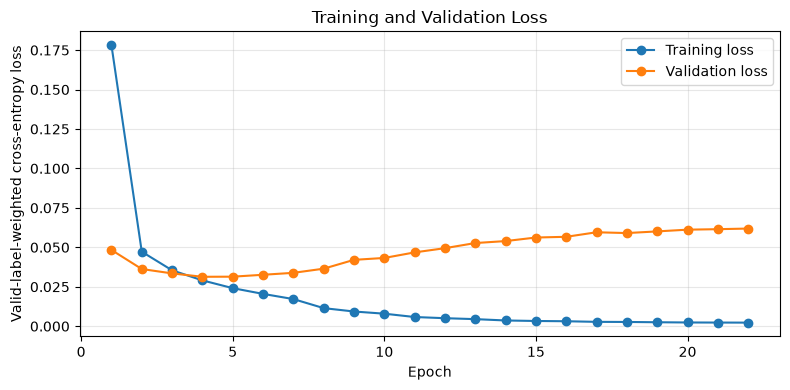

In [32]:
import matplotlib.pyplot as plt

completed_epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 4))
plt.plot(completed_epochs, history["train_loss"], marker="o", label="Training loss")
plt.plot(
    completed_epochs,
    history["validation_loss"],
    marker="o",
    label="Validation loss",
)
plt.xlabel("Epoch")
plt.ylabel("Valid-label-weighted cross-entropy loss")
plt.title("Training and Validation Loss")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

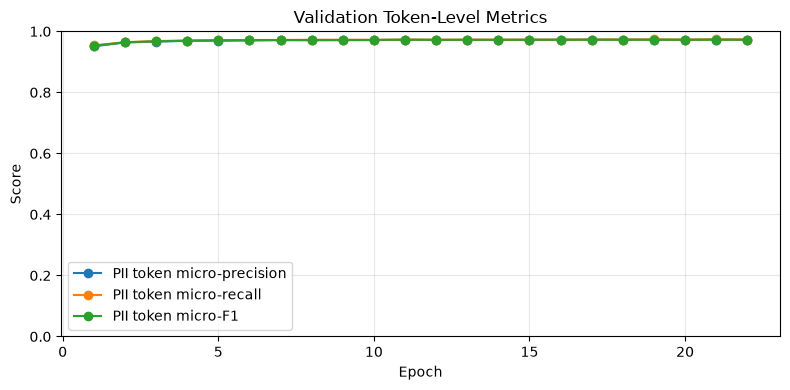

In [33]:
plt.figure(figsize=(8, 4))
for metric_name, label in [
    ("validation_pii_token_micro_precision", "PII token micro-precision"),
    ("validation_pii_token_micro_recall", "PII token micro-recall"),
    ("validation_pii_token_micro_f1", "PII token micro-F1"),
]:
    plt.plot(completed_epochs, history[metric_name], marker="o", label=label)
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Validation Token-Level Metrics")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

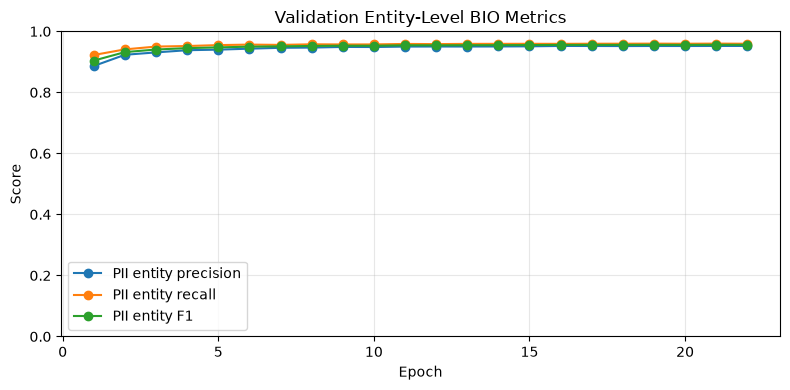

In [34]:
plt.figure(figsize=(8, 4))
for metric_name, label in [
    ("validation_pii_entity_precision", "PII entity precision"),
    ("validation_pii_entity_recall", "PII entity recall"),
    ("validation_pii_entity_f1", "PII entity F1"),
]:
    plt.plot(completed_epochs, history[metric_name], marker="o", label=label)
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Validation Entity-Level BIO Metrics")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

#### 19. Complete Example Predictions

Use the restored best model. Text that fits is processed without truncation; oversized text uses the same overlapping-window strategy as the dataset. Window predictions are merged into original character offsets before one complete masked string is reconstructed.

In [35]:
def mask_text_from_spans(source_text, predicted_spans):
    masked_parts = []
    entity_counts = Counter()
    source_cursor = 0

    for span in predicted_spans:
        if span["start"] < source_cursor:
            continue
        masked_parts.append(source_text[source_cursor:span["start"]])
        entity_type = span["entity_type"]
        entity_counts[entity_type] += 1
        masked_parts.append(f"[{entity_type}_{entity_counts[entity_type]}]")
        source_cursor = span["end"]

    masked_parts.append(source_text[source_cursor:])
    return "".join(masked_parts)


def predict_complete_text_pytorch(source_text):
    windows = tokenize_example_windows(
        source_text,
        [],
        "deployment input",
        0,
    )
    full_encoding = tokenizer(
        source_text,
        truncation=False,
        padding=False,
        return_offsets_mapping=True,
        return_attention_mask=False,
        return_token_type_ids=False,
    )
    reference_offsets = [
        tuple(offset)
        for offset in full_encoding["offset_mapping"]
        if offset[0] != offset[1]
    ]
    references = [{
        "example_index": 0,
        "offsets": reference_offsets,
        "true_labels": ["O"] * len(reference_offsets),
    }]

    window_records = []
    model.eval()
    for start in range(0, len(windows), BATCH_SIZE):
        batch = collate_token_classification_batch(
            windows[start:start + BATCH_SIZE]
        )
        with torch.no_grad():
            logits = model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device),
            ).logits
        probabilities = torch.softmax(logits, dim=-1)
        confidences, predictions = probabilities.max(dim=-1)

        for row_index, example_index in enumerate(batch["example_indices"]):
            offsets = batch["offset_mappings"][row_index]
            sequence_length = len(offsets)
            window_records.append({
                "example_index": int(example_index),
                "offsets": offsets,
                "predicted_label_ids": predictions[
                    row_index, :sequence_length
                ].cpu().tolist(),
                "confidences": confidences[
                    row_index, :sequence_length
                ].cpu().tolist(),
            })

    _, predicted_sequences, repair_count = merge_window_predictions(
        window_records,
        references,
    )
    predicted_spans = labels_to_character_spans(
        reference_offsets,
        predicted_sequences[0],
    )
    masked_text = mask_text_from_spans(source_text, predicted_spans)
    return masked_text, predicted_spans, repair_count

In [36]:
prediction_example_count = min(5, len(scored_final_test_dataset))
prediction_rng = random.Random(SEED)
prediction_indices = prediction_rng.sample(
    range(len(scored_final_test_dataset)),
    k=prediction_example_count,
)

prediction_rows = []
example_bio_repair_count = 0
for example_index in prediction_indices:
    example = scored_final_test_dataset[example_index]
    predicted_masked_text, _, repair_count = predict_complete_text_pytorch(
        example["source_text"]
    )
    example_bio_repair_count += repair_count
    prediction_rows.append({
        "Original source text": example["source_text"],
        "Expected masked text": example["masked_text"],
        "Predicted masked text": predicted_masked_text,
    })

print(
    "Invalid BIO transitions repaired across displayed examples:",
    example_bio_repair_count,
)
pd.DataFrame(prediction_rows)

Invalid BIO transitions repaired across displayed examples: 0


,Original source text,Expected masked text,Predicted masked text
0,"Mstr Nadera Cherruault Buddensieck, a botanist specializing in Antarctic flora, will present their findings on the biodiversity of mosses and lichens at the upcoming conference on December 20th, 1955. The study, funded under grant number 70568.52728, includes field samples collected near the Runningbrook Drive research station, building 888 in Saint-Gervais, and complies with the ethical standards for specimens of individuals born on 1974-08-13T00:00:00 who are aged 41 years and identify as Male. For further information or to request a copy of the dataset, please contact Kirupananthan Celica at agremillet@tutanota.com or call 01806.63 164.8576; the mailing address is Mountain Highway 49, Saint Rita, P0A 1H0, Canada.","[TITLE_1] [GIVENNAME_2] [SURNAME_2], a botanist specializing in Antarctic flora, will present their findings on the biodiversity of mosses and lichens at the upcoming conference on [DATE_2]. The study, funded under grant number [TAXNUM_1], includes field samples collected near the [STREET_2] research station, building [BUILDINGNUM_2] in [CITY_2], and complies with the ethical standards for specimens of individuals born on [DATE_1] who are aged [AGE_1] years and identify as [GENDER_1]. For further information or to request a copy of the dataset, please contact [GIVENNAME_1] [SURNAME_1] at [EMAIL_1] or call [TELEPHONENUM_1]; the mailing address is [STREET_1] [BUILDINGNUM_1], [CITY_1], [ZIPCODE_1], Canada.","[TITLE_1] [GIVENNAME_1] [SURNAME_1], a botanist specializing in Antarctic flora, will present their findings on the biodiversity of mosses and lichens at the upcoming conference on [DATE_1]. The study, funded under grant number [TAXNUM_1], includes field samples collected near the [STREET_1] research station, building [BUILDINGNUM_1] in [CITY_1], and complies with the ethical standards for specimens of individuals born on [DATE_2] who are aged [AGE_1] years and identify as [GENDER_1]. For further information or to request a copy of the dataset, please contact [GIVENNAME_2] at [EMAIL_1] or call [TELEPHONENUM_1]; the mailing address is [STREET_2], [CITY_2], [ZIPCODE_1], Canada."
1,"Form: Family Fund Gift Declaration (Short)\n\n1. Donor Name: Mister Nysa Roggenbuck\n2. Donor DOB: 17/02/2021\n3. Donor Tax ID: S0082467T\n4. Recipient Name: Yicheng Ünesen Renirkens\n5. Recipient DOB: February/86\n6. Relationship: Not specified\n7. Gift Amount (USD): 4415642985761651 (masked)\n8. Recipient Address: 5069 Boon Lay Drive, Singapore 372082\n9. Signature: ________________________ Date: February 19th, 1950","Form: Family Fund Gift Declaration (Short)\n\n1. Donor Name: [TITLE_1] [GIVENNAME_2] [SURNAME_2]\n2. Donor DOB: [DATE_3]\n3. Donor Tax ID: [TAXNUM_1]\n4. Recipient Name: [GIVENNAME_1] [SURNAME_1]\n5. Recipient DOB: [DATE_2]\n6. Relationship: [GENDER_1]\n7. Gift Amount (USD): [CREDITCARDNUMBER_1] (masked)\n8. Recipient Address: [BUILDINGNUM_1] [STREET_1], [CITY_1] [ZIPCODE_1]\n9. Signature: ________________________ Date: [DATE_1]","Form: Family Fund Gift Declaration (Short)\n\n1. Donor Name: [TITLE_1] [GIVENNAME_1] [SURNAME_1]\n2. Donor DOB: [DATE_1]\n3. Donor Tax ID: [TAXNUM_1]\n4. Recipient Name: [GIVENNAME_2] [SURNAME_2]\n5. Recipient DOB: [DATE_2]\n6. Relationship: [GENDER_1]\n7. Gift Amount (USD): [CREDITCARDNUMBER_1] (masked)\n8. Recipient Address: [BUILDINGNUM_1] [STREET_1], [CITY_1] [ZIPCODE_1]\n9. Signature: ________________________ Date: [DATE_3]"
2,"Subject: Launch of the Hierarchical Structure Redesign Guide\nDear Mister Ciel Domingas,\nWe are pleased to announce that the new guide, version 2.0, will be available from August/22 and will be distributed from our headquarters at 408 Cow Fen Road, Sherborne TA5.\nThe document outlines a streamlined reporting line, clarifies decision‑making authority, and introduces a matrix overlay for cross‑functional projects.\nPlease review the attached PDF and forward any comments to the redesign team at 21S@g

#### 20. Leakage-Safety Explanation

- Project training and validation come only from the official English training split.
- The untouched official English validation split remains separately available as `original_final_test_dataset`.
- Unsupported final-test entity types are discovered dynamically; every affected row is excluded only from `scored_final_test_dataset`.
- Final-test losses and metrics never affect the scheduler, early stopping, checkpoint selection, or resume state.
- No normal dataset row or inference input is silently truncated. Oversized text is covered by overlapping windows and merged back into original character offsets.
- Invalid predicted BIO transitions are normalized before entity metrics, reconstruction, displayed masking, and privacy leakage evaluation.
- Private-character leakage is the fraction of true private characters left unmasked. Private-character recall is its complement. Over-masking is the fraction of non-private characters masked. Exact-span recall uses exact ground-truth and predicted character boundaries, independent of entity type.

Counts and rates are reported without printing real PII values.

#### 21. Save Restored FP32 Artifacts and Export Dynamic ONNX

Save only the restored best validation model. Keep Hugging Face weights, tokenizer files, ONNX files, metrics, configuration, and checkpoints in clearly separate directories under the single portable artifact root.

In [37]:
model.save_pretrained(HUGGINGFACE_MODEL_DIRECTORY)
tokenizer.save_pretrained(TOKENIZER_DIRECTORY)

with (CONFIG_DIRECTORY / "label2id.json").open("w", encoding="utf-8") as file:
    json.dump(label2id, file, indent=2, ensure_ascii=False)

with (CONFIG_DIRECTORY / "id2label.json").open("w", encoding="utf-8") as file:
    json.dump(
        {str(label_id): label for label_id, label in id2label.items()},
        file,
        indent=2,
        ensure_ascii=False,
    )

training_config = {
    "dataset_name": DATASET_NAME,
    "dataset_revision": DATASET_REVISION,
    "dataset_fingerprints": {
        "official_train": official_training_dataset._fingerprint,
        "project_train": project_train_dataset._fingerprint,
        "project_validation": project_validation_dataset._fingerprint,
        "untouched_official_final_test": original_final_test_dataset._fingerprint,
        "scored_final_test": scored_final_test_dataset._fingerprint,
    },
    "model_name": MODEL_NAME,
    "model_revision": MODEL_REVISION,
    "seed": SEED,
    "validation_size": VALIDATION_SIZE,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "validation_batch_size": VALIDATION_BATCH_SIZE,
    "final_test_batch_size": FINAL_TEST_BATCH_SIZE,
    "dynamic_padding": "longest sequence in each batch",
    "pad_to_multiple_of": PAD_TO_MULTIPLE_OF,
    "label_pad_token_id": -100,
    "dataloader_num_workers": DATALOADER_NUM_WORKERS,
    "pin_memory": PIN_MEMORY,
    "non_blocking_transfers": NON_BLOCKING_TRANSFERS,
    "use_mixed_precision": bool(amp_enabled),
    "amp_dtype": str(AMP_DTYPE),
    "tf32_matmul_enabled": tf32_matmul_enabled,
    "tf32_cudnn_enabled": tf32_cudnn_enabled,
    "supported_context_limit": supported_context_limit,
    "overflow_stride": OVERFLOW_STRIDE,
    "sequence_length_audit": sequence_length_audit,
    "epochs_configured": EPOCHS,
    "epochs_completed": len(history["train_loss"]),
    "best_epoch": best_epoch,
    "best_validation_metric_name": best_validation_metric_name,
    "best_validation_metric": best_validation_metric,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_occurred": early_stopping_occurred,
    "resume_training": RESUME_TRAINING,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "use_weighted_loss": USE_WEIGHTED_LOSS,
    "o_label_weight": O_LABEL_WEIGHT,
    "pii_label_weight": PII_LABEL_WEIGHT,
    "use_lr_scheduler": USE_LR_SCHEDULER,
    "lr_scheduler": "ReduceLROnPlateau" if scheduler is not None else None,
    "unsupported_final_test_entity_types": sorted(
        unsupported_final_test_types
    ),
    "unsupported_final_test_rows": len(unsupported_final_test_row_indices),
    "unsupported_final_test_spans": dict(unsupported_final_test_span_counts),
}

with (CONFIG_DIRECTORY / "training_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(training_config, file, indent=2, ensure_ascii=False)

with (CONFIG_DIRECTORY / "environment_versions.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(environment_versions, file, indent=2, ensure_ascii=False)

with (METRICS_DIRECTORY / "training_history.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(history, file, indent=2, ensure_ascii=False)

with (METRICS_DIRECTORY / "final_test_fp32_pytorch.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(fp32_metrics, file, indent=2, ensure_ascii=False)

print("Saved restored best Hugging Face model and tokenizer.")
print("Artifact root:", ARTIFACT_ROOT.resolve())

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.73it/s]

Saved restored best Hugging Face model and tokenizer.
Artifact root: <REPO_ROOT>/model/TinyBERT-4/artifacts/tinybert_pii


Export logits with dynamic batch and sequence dimensions. Try the modern Dynamo exporter first. If it fails, print the reason and use the documented legacy `dynamic_axes` fallback at opset 17.

In [38]:
fp32_onnx_path = ONNX_MODEL_DIRECTORY / "model_fp32.onnx"
original_model_device = next(model.parameters()).device
original_return_dict = model.config.return_dict

export_inputs = tokenizer(
    [
        "TinyBERT ONNX export shape check.",
        "A second and deliberately longer sentence keeps both exported axes dynamic.",
    ],
    truncation=False,
    padding=True,
    return_attention_mask=True,
    return_token_type_ids=False,
    return_tensors="pt",
)

try:
    model.to("cpu")
    model.eval()
    model.config.return_dict = False

    batch_dimension = torch.export.Dim("batch_size", min=1)
    sequence_dimension = torch.export.Dim(
        "sequence_length",
        min=1,
        max=supported_context_limit,
    )

    try:
        onnx_program = torch.onnx.export(
            model,
            args=(
                export_inputs["input_ids"],
                export_inputs["attention_mask"],
            ),
            input_names=["input_ids", "attention_mask"],
            output_names=["logits"],
            opset_version=17,
            dynamo=True,
            external_data=False,
            dynamic_shapes=(
                {0: batch_dimension, 1: sequence_dimension},
                {0: batch_dimension, 1: sequence_dimension},
            ),
        )
        onnx_program.save(fp32_onnx_path, external_data=False)
        onnx_exporter_used = "torch.onnx.export Dynamo"
    except Exception as dynamo_export_error:
        print("Dynamo ONNX export failed; using legacy dynamic_axes fallback.")
        print(type(dynamo_export_error).__name__, str(dynamo_export_error)[:500])
        torch.onnx.export(
            model,
            args=(
                export_inputs["input_ids"],
                export_inputs["attention_mask"],
            ),
            f=str(fp32_onnx_path),
            input_names=["input_ids", "attention_mask"],
            output_names=["logits"],
            opset_version=17,
            dynamo=False,
            dynamic_axes={
                "input_ids": {0: "batch_size", 1: "sequence_length"},
                "attention_mask": {0: "batch_size", 1: "sequence_length"},
                "logits": {0: "batch_size", 1: "sequence_length"},
            },
        )
        onnx_exporter_used = "torch.onnx.export legacy dynamic_axes fallback"
finally:
    model.config.return_dict = original_return_dict
    model.to(original_model_device)

print("FP32 ONNX exporter:", onnx_exporter_used)
print("FP32 ONNX path:", fp32_onnx_path)

W0717 11:40:00.371000 24028 Lib\site-packages\torch\onnx\_internal\exporter\_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0717 11:40:03.005000 24028 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:110] torchvision is not installed. Skipping torchvision::nms
W0717 11:40:03.009000 24028 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:110] torchvision is not installed. Skipping torchvision::roi_align
W0717 11:40:03.012000 24028 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:110] torchvision is not installed. Skipping torchvision::roi_pool

[torch.onnx] Obtain model graph for `BertForTokenClassification([...]` with `torch.export.export(..., strict=False)`...


W0717 11:40:03.460000 24028 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


[torch.onnx] Obtain model graph for `BertForTokenClassification([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


<LOCAL_PATH>/copyreg.py:105: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


<REPO_ROOT>/.venv/Lib/site-packages/torch/onnx/_internal/exporter/_onnx_program.py:487: UserWarning: # The axis name: batch_size will not be used, since it shares the same shape constraints with another axis: batch_size.
  rename_mapping = _dynamic_shapes.create_rename_mapping(
<REPO_ROOT>/.venv/Lib/site-packages/torch/onnx/_internal/exporter/_onnx_program.py:487: UserWarning: # The axis name: sequence_length will not be used, since it shares the same shape constraints with another axis: sequence_length.
  rename_mapping = _dynamic_shapes.create_rename_mapping(


FP32 ONNX exporter: torch.onnx.export Dynamo
FP32 ONNX path: artifacts\tinybert_pii\onnx_model\model_fp32.onnx


In [39]:
fp32_onnx_model = onnx.load(str(fp32_onnx_path))
onnx.checker.check_model(fp32_onnx_model)

fp32_session_check = ort.InferenceSession(
    str(fp32_onnx_path),
    providers=["CPUExecutionProvider"],
)

onnx_dynamic_shape_checks = []
for shape_check_texts in [
    ["Short dynamic input."],
    [
        "One medium dynamic input for the first row.",
        "A second row with a different sentence makes the batch dimension equal two.",
    ],
]:
    encoded_shape_check = tokenizer(
        shape_check_texts,
        truncation=False,
        padding=True,
        return_attention_mask=True,
        return_token_type_ids=False,
        return_tensors="np",
    )
    shape_check_inputs = {
        "input_ids": encoded_shape_check["input_ids"],
        "attention_mask": encoded_shape_check["attention_mask"],
    }
    shape_check_logits = fp32_session_check.run(
        ["logits"],
        shape_check_inputs,
    )[0]
    expected_shape = (
        shape_check_inputs["input_ids"].shape[0],
        shape_check_inputs["input_ids"].shape[1],
        num_labels,
    )
    assert shape_check_logits.shape == expected_shape
    onnx_dynamic_shape_checks.append(expected_shape)

assert (
    onnx_dynamic_shape_checks[0][1]
    != onnx_dynamic_shape_checks[1][1]
)
print("ONNX checker: passed")
print("ONNX Runtime dynamic shape checks:", onnx_dynamic_shape_checks)

ONNX checker: passed
ONNX Runtime dynamic shape checks: [(1, 6, 67), (2, 16, 67)]


#### 22. Create and Validate the INT8 ONNX Model

Quantize the checked FP32 ONNX model with ONNX Runtime dynamic QInt8 weights. Keep both ONNX files in the explicit `onnx_model` directory, then checker-validate, load, and run the INT8 model at two sequence lengths.

In [40]:
from onnxruntime.quantization import QuantType, quantize_dynamic

int8_onnx_path = ONNX_MODEL_DIRECTORY / "model_int8.onnx"
quantize_dynamic(
    model_input=str(fp32_onnx_path),
    model_output=str(int8_onnx_path),
    weight_type=QuantType.QInt8,
    per_channel=False,
    reduce_range=False,
)

int8_onnx_model = onnx.load(str(int8_onnx_path))
onnx.checker.check_model(int8_onnx_model)
int8_session_check = ort.InferenceSession(
    str(int8_onnx_path),
    providers=["CPUExecutionProvider"],
)

int8_dynamic_shape_checks = []
for shape_check_texts in [
    ["Short INT8 input."],
    [
        "A somewhat longer INT8 input verifies another sequence length.",
        "The second row also verifies dynamic batch size two.",
    ],
]:
    encoded_shape_check = tokenizer(
        shape_check_texts,
        truncation=False,
        padding=True,
        return_attention_mask=True,
        return_token_type_ids=False,
        return_tensors="np",
    )
    shape_check_inputs = {
        "input_ids": encoded_shape_check["input_ids"],
        "attention_mask": encoded_shape_check["attention_mask"],
    }
    shape_check_logits = int8_session_check.run(
        ["logits"],
        shape_check_inputs,
    )[0]
    expected_shape = (
        shape_check_inputs["input_ids"].shape[0],
        shape_check_inputs["input_ids"].shape[1],
        num_labels,
    )
    assert shape_check_logits.shape == expected_shape
    int8_dynamic_shape_checks.append(expected_shape)

assert int8_dynamic_shape_checks[0][1] != int8_dynamic_shape_checks[1][1]

quantization_config = {
    "method": "ONNX Runtime dynamic post-training quantization",
    "weight_type": "QInt8",
    "per_channel": False,
    "reduce_range": False,
    "source_model": str(fp32_onnx_path.relative_to(ARTIFACT_ROOT)),
    "int8_model": str(int8_onnx_path.relative_to(ARTIFACT_ROOT)),
    "onnx_exporter": onnx_exporter_used,
    "opset": int(fp32_onnx_model.opset_import[0].version),
    "onnxruntime_version": ort.__version__,
}
with (CONFIG_DIRECTORY / "quantization_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(quantization_config, file, indent=2, ensure_ascii=False)

print("INT8 ONNX checker and runtime shape checks: passed")
print("INT8 ONNX path:", int8_onnx_path)

INT8 ONNX checker and runtime shape checks: passed
INT8 ONNX path: artifacts\tinybert_pii\onnx_model\model_int8.onnx


#### 23. Evaluate and Benchmark FP32 versus INT8

Evaluate both ONNX models on identical complete final-test windows and merge predictions back to original rows. Benchmark a bounded host-machine sample separately: warm up both models, alternate randomized execution order, repeat measurements, report latency and throughput, and include batch-size-1 results and ONNX Runtime thread settings. These are not Raspberry Pi measurements.

In [41]:
fp32_session_options = ort.SessionOptions()
fp32_session_options.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)
int8_session_options = ort.SessionOptions()
int8_session_options.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)

fp32_onnx_session = ort.InferenceSession(
    str(fp32_onnx_path),
    sess_options=fp32_session_options,
    providers=["CPUExecutionProvider"],
)
int8_onnx_session = ort.InferenceSession(
    str(int8_onnx_path),
    sess_options=int8_session_options,
    providers=["CPUExecutionProvider"],
)

onnxruntime_thread_settings = {
    "fp32_intra_op_num_threads": fp32_session_options.intra_op_num_threads,
    "fp32_inter_op_num_threads": fp32_session_options.inter_op_num_threads,
    "int8_intra_op_num_threads": int8_session_options.intra_op_num_threads,
    "int8_inter_op_num_threads": int8_session_options.inter_op_num_threads,
    "note": "0 means ONNX Runtime default thread selection",
}
print("ONNX Runtime thread settings:")
for setting_name, setting_value in onnxruntime_thread_settings.items():
    print(f"  {setting_name}: {setting_value}")

ONNX Runtime thread settings:
  fp32_intra_op_num_threads: 0
  fp32_inter_op_num_threads: 0
  int8_intra_op_num_threads: 0
  int8_inter_op_num_threads: 0
  note: 0 means ONNX Runtime default thread selection


In [42]:
def numpy_predictions_and_confidences(logits):
    shifted_logits = logits - logits.max(axis=-1, keepdims=True)
    probabilities = np.exp(shifted_logits)
    probabilities /= probabilities.sum(axis=-1, keepdims=True)
    predictions = probabilities.argmax(axis=-1)
    confidences = probabilities.max(axis=-1)
    return predictions, confidences


onnx_window_records = {
    "FP32 ONNX": [],
    "INT8 ONNX": [],
}

for batch in final_test_dataloader:
    model_inputs = {
        "input_ids": batch["input_ids"].cpu().numpy(),
        "attention_mask": batch["attention_mask"].cpu().numpy(),
    }
    logits_by_model = {
        "FP32 ONNX": fp32_onnx_session.run(["logits"], model_inputs)[0],
        "INT8 ONNX": int8_onnx_session.run(["logits"], model_inputs)[0],
    }

    for model_name, logits in logits_by_model.items():
        predictions, confidences = numpy_predictions_and_confidences(logits)
        for row_index, example_index in enumerate(batch["example_indices"]):
            offsets = batch["offset_mappings"][row_index]
            sequence_length = len(offsets)
            onnx_window_records[model_name].append({
                "example_index": int(example_index),
                "offsets": offsets,
                "predicted_label_ids": predictions[
                    row_index, :sequence_length
                ].tolist(),
                "confidences": confidences[
                    row_index, :sequence_length
                ].tolist(),
            })

onnx_metrics_by_model = {}
onnx_predicted_sequences = {}
for model_name, window_records in onnx_window_records.items():
    true_sequences, predicted_sequences, repair_count = (
        merge_window_predictions(window_records, final_test_references)
    )
    token_metrics = compute_token_metrics(true_sequences, predicted_sequences)
    entity_metrics = compute_entity_metrics(true_sequences, predicted_sequences)
    privacy_metrics = compute_privacy_metrics(
        scored_final_test_dataset,
        final_test_references,
        predicted_sequences,
    )
    model_path = fp32_onnx_path if model_name == "FP32 ONNX" else int8_onnx_path
    onnx_metrics_by_model[model_name] = {
        "token_level": token_metrics,
        "entity_level": entity_metrics,
        "privacy": privacy_metrics,
        "invalid_bio_transitions_repaired": int(repair_count),
        "model_size_mb": float(model_path.stat().st_size / (1024 ** 2)),
    }
    onnx_predicted_sequences[model_name] = predicted_sequences

print("Completed full scored final-test ONNX quality evaluation.")

Completed full scored final-test ONNX quality evaluation.


In [43]:
benchmark_inputs = []
benchmark_example_counts = []
for batch_index, batch in enumerate(final_test_dataloader):
    if batch_index >= ONNX_BENCHMARK_BATCHES:
        break
    benchmark_inputs.append({
        "input_ids": batch["input_ids"].cpu().numpy(),
        "attention_mask": batch["attention_mask"].cpu().numpy(),
    })
    benchmark_example_counts.append(int(batch["input_ids"].shape[0]))

if not benchmark_inputs:
    raise ValueError("No inputs are available for the ONNX benchmark.")

benchmark_sessions = {
    "FP32 ONNX": fp32_onnx_session,
    "INT8 ONNX": int8_onnx_session,
}
for _ in range(ONNX_WARMUP_RUNS):
    for model_inputs in benchmark_inputs:
        for session in benchmark_sessions.values():
            session.run(["logits"], model_inputs)

benchmark_rng = random.Random(SEED)
batch_latencies = {model_name: [] for model_name in benchmark_sessions}
total_timed_examples = {model_name: 0 for model_name in benchmark_sessions}

for _ in range(ONNX_BENCHMARK_REPETITIONS):
    for model_inputs, example_count in zip(
        benchmark_inputs,
        benchmark_example_counts,
    ):
        model_order = list(benchmark_sessions)
        benchmark_rng.shuffle(model_order)
        for model_name in model_order:
            start_time = time.perf_counter()
            benchmark_sessions[model_name].run(["logits"], model_inputs)
            batch_latencies[model_name].append(time.perf_counter() - start_time)
            total_timed_examples[model_name] += example_count

single_feature_batch = collate_token_classification_batch(
    [tokenized_final_test_dataset[0]]
)
batch_size_one_inputs = {
    "input_ids": single_feature_batch["input_ids"].cpu().numpy(),
    "attention_mask": single_feature_batch["attention_mask"].cpu().numpy(),
}
batch_size_one_latencies = {
    model_name: [] for model_name in benchmark_sessions
}
for _ in range(ONNX_WARMUP_RUNS):
    for session in benchmark_sessions.values():
        session.run(["logits"], batch_size_one_inputs)

for _ in range(ONNX_BENCHMARK_REPETITIONS * 5):
    model_order = list(benchmark_sessions)
    benchmark_rng.shuffle(model_order)
    for model_name in model_order:
        start_time = time.perf_counter()
        benchmark_sessions[model_name].run(["logits"], batch_size_one_inputs)
        batch_size_one_latencies[model_name].append(
            time.perf_counter() - start_time
        )

for model_name in benchmark_sessions:
    latencies = np.asarray(batch_latencies[model_name], dtype=float)
    batch_one = np.asarray(batch_size_one_latencies[model_name], dtype=float)
    total_seconds = float(latencies.sum())
    onnx_metrics_by_model[model_name]["host_machine_benchmark"] = {
        "mean_batch_latency_ms": float(1000 * latencies.mean()),
        "median_batch_latency_ms": float(1000 * np.median(latencies)),
        "batch_size_one_mean_latency_ms": float(1000 * batch_one.mean()),
        "batch_size_one_median_latency_ms": float(1000 * np.median(batch_one)),
        "throughput_examples_per_second": float(
            total_timed_examples[model_name] / total_seconds
        ),
        "timed_examples_including_repetitions": int(
            total_timed_examples[model_name]
        ),
        "repetitions": ONNX_BENCHMARK_REPETITIONS,
        "warmup_runs": ONNX_WARMUP_RUNS,
        "benchmark_batches": len(benchmark_inputs),
        "execution_provider": "CPUExecutionProvider",
        "thread_settings": onnxruntime_thread_settings,
        "measurement_scope": "host machine; not Raspberry Pi",
    }

print("Host-machine benchmark complete. These are not Raspberry Pi results.")

Host-machine benchmark complete. These are not Raspberry Pi results.


Present token, entity, privacy, size, latency, and throughput results together. Signed differences are INT8 minus FP32.

In [44]:
fp32_onnx_metrics = onnx_metrics_by_model["FP32 ONNX"]
int8_metrics = onnx_metrics_by_model["INT8 ONNX"]

onnx_comparison = {
    "difference_definition": "INT8 minus FP32",
    "pii_token_micro_f1_difference": (
        int8_metrics["token_level"]["pii_token_micro_f1"]
        - fp32_onnx_metrics["token_level"]["pii_token_micro_f1"]
    ),
    "pii_entity_f1_difference": (
        int8_metrics["entity_level"]["pii_entity_f1"]
        - fp32_onnx_metrics["entity_level"]["pii_entity_f1"]
    ),
    "private_character_leakage_rate_difference": (
        int8_metrics["privacy"]["private_character_leakage_rate"]
        - fp32_onnx_metrics["privacy"]["private_character_leakage_rate"]
    ),
    "model_size_difference_mb": (
        int8_metrics["model_size_mb"] - fp32_onnx_metrics["model_size_mb"]
    ),
    "batch_size_one_mean_latency_difference_ms": (
        int8_metrics["host_machine_benchmark"]["batch_size_one_mean_latency_ms"]
        - fp32_onnx_metrics["host_machine_benchmark"]["batch_size_one_mean_latency_ms"]
    ),
}

comparison_df = pd.DataFrame([
    {
        "Model": model_name,
        "PII token micro-F1": metrics["token_level"]["pii_token_micro_f1"],
        "PII entity F1": metrics["entity_level"]["pii_entity_f1"],
        "Private-character leakage": metrics["privacy"][
            "private_character_leakage_rate"
        ],
        "Size (MB)": metrics["model_size_mb"],
        "Batch-1 mean latency (ms)": metrics["host_machine_benchmark"][
            "batch_size_one_mean_latency_ms"
        ],
        "Throughput (examples/s)": metrics["host_machine_benchmark"][
            "throughput_examples_per_second"
        ],
    }
    for model_name, metrics in onnx_metrics_by_model.items()
])

comparison_df

,Model,PII token micro-F1,PII entity F1,Private-character leakage,Size (MB),Batch-1 mean latency (ms),Throughput (examples/s)
0,FP32 ONNX,0.973088,0.956507,0.002724,54.494267,144.210564,17.532651
1,INT8 ONNX,0.969598,0.949619,0.003113,13.720334,129.921056,18.953003


In [45]:
int8_per_entity_type_df = pd.DataFrame.from_dict(
    int8_metrics["entity_level"]["per_entity_type"],
    orient="index",
).reset_index(names="Entity type")

print("INT8 minus FP32 differences:")
for metric_name, difference in onnx_comparison.items():
    if metric_name != "difference_definition":
        print(f"  {metric_name}: {difference:.6f}")

int8_per_entity_type_df

INT8 minus FP32 differences:
  pii_token_micro_f1_difference: -0.003490
  pii_entity_f1_difference: -0.006888
  private_character_leakage_rate_difference: 0.000390
  model_size_difference_mb: -40.773933
  batch_size_one_mean_latency_difference_ms: -14.289508


,Entity type,precision,recall,f1,support
0,ACCOUNTNUM,0.000000,0.000000,0.000000,1
1,AGE,0.957624,0.984878,0.971060,15144
2,AMOUNT,0.000000,0.000000,0.000000,2
3,BANKNAME,0.000000,0.000000,0.000000,1
4,BUILDINGNUM,0.983273,0.986912,0.985089,14593
5,CITY,0.967031,0.978368,0.972667,21496
6,COUNTRY,0.000000,0.000000,0.000000,2
7,CREDITCARDNUMBER,0.992580,0.996868,0.994719,9259
8,CURRENCY,0.000000,0.000000,0.000000,2
9,DATE,0.996401,0.999011,0.997704,37412


In [46]:
with (METRICS_DIRECTORY / "onnx_quality_and_benchmark.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(
        {
            "models": onnx_metrics_by_model,
            "comparison": onnx_comparison,
        },
        file,
        indent=2,
        ensure_ascii=False,
    )

with (METRICS_DIRECTORY / "all_final_metrics.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(
        {
            "pytorch_fp32": fp32_metrics,
            "onnx_models": onnx_metrics_by_model,
            "onnx_comparison": onnx_comparison,
        },
        file,
        indent=2,
        ensure_ascii=False,
    )

print("Saved final metrics under:", METRICS_DIRECTORY.resolve())

Saved final metrics under: <REPO_ROOT>/model/TinyBERT-4/artifacts/tinybert_pii/metrics


#### 24. Reload and Smoke-Test the Saved INT8 Pipeline

Reload the saved tokenizer and accepted INT8 ONNX model. The inference helper uses full no-truncation inference when text fits and overlapping dynamic windows when it does not. The harmless fictional sentence verifies shape compatibility, BIO normalization, complete reconstruction, and artifact interoperability; it does not assert prediction quality.

In [47]:
accepted_tokenizer = AutoTokenizer.from_pretrained(
    TOKENIZER_DIRECTORY,
    local_files_only=True,
    use_fast=True,
)
accepted_int8_session = ort.InferenceSession(
    str(int8_onnx_path),
    providers=["CPUExecutionProvider"],
)


def predict_complete_text_onnx(source_text, inference_tokenizer, session):
    full_encoding = inference_tokenizer(
        source_text,
        truncation=False,
        padding=False,
        return_attention_mask=True,
        return_offsets_mapping=True,
        return_token_type_ids=False,
    )

    if len(full_encoding["input_ids"]) <= supported_context_limit:
        window_encodings = [{
            "input_ids": full_encoding["input_ids"],
            "attention_mask": full_encoding["attention_mask"],
            "offset_mapping": full_encoding["offset_mapping"],
        }]
    else:
        overflow_encoding = inference_tokenizer(
            source_text,
            truncation=True,  # Intentional complete-text overflow path.
            max_length=supported_context_limit,
            stride=OVERFLOW_STRIDE,
            padding=False,
            return_attention_mask=True,
            return_offsets_mapping=True,
            return_overflowing_tokens=True,
            return_token_type_ids=False,
        )
        window_encodings = [
            {
                "input_ids": input_ids,
                "attention_mask": attention_mask,
                "offset_mapping": offset_mapping,
            }
            for input_ids, attention_mask, offset_mapping in zip(
                overflow_encoding["input_ids"],
                overflow_encoding["attention_mask"],
                overflow_encoding["offset_mapping"],
            )
        ]

    reference_offsets = [
        tuple(offset)
        for offset in full_encoding["offset_mapping"]
        if offset[0] != offset[1]
    ]
    references = [{
        "example_index": 0,
        "offsets": reference_offsets,
        "true_labels": ["O"] * len(reference_offsets),
    }]
    window_records = []

    for start in range(0, len(window_encodings), BATCH_SIZE):
        window_batch = window_encodings[start:start + BATCH_SIZE]
        padded_batch = inference_tokenizer.pad(
            [
                {
                    "input_ids": window["input_ids"],
                    "attention_mask": window["attention_mask"],
                }
                for window in window_batch
            ],
            padding="longest",
            return_tensors="np",
        )
        model_inputs = {
            "input_ids": padded_batch["input_ids"],
            "attention_mask": padded_batch["attention_mask"],
        }
        logits = session.run(["logits"], model_inputs)[0]
        predictions, confidences = numpy_predictions_and_confidences(logits)

        if logits.shape != (
            model_inputs["input_ids"].shape[0],
            model_inputs["input_ids"].shape[1],
            num_labels,
        ):
            raise RuntimeError("INT8 logits shape does not match dynamic inputs.")

        for row_index, window in enumerate(window_batch):
            sequence_length = len(window["offset_mapping"])
            window_records.append({
                "example_index": 0,
                "offsets": window["offset_mapping"],
                "predicted_label_ids": predictions[
                    row_index, :sequence_length
                ].tolist(),
                "confidences": confidences[
                    row_index, :sequence_length
                ].tolist(),
            })

    _, predicted_sequences, repair_count = merge_window_predictions(
        window_records,
        references,
    )
    predicted_spans = labels_to_character_spans(
        reference_offsets,
        predicted_sequences[0],
    )
    masked_text = mask_text_from_spans(source_text, predicted_spans)
    return masked_text, predicted_spans, repair_count


smoke_test_text = "Contact Alex Example at alex@example.com."
smoke_masked_text, smoke_spans, smoke_repair_count = (
    predict_complete_text_onnx(
        smoke_test_text,
        accepted_tokenizer,
        accepted_int8_session,
    )
)

print("Accepted INT8 end-to-end smoke test: passed")
print("Synthetic input length:", len(smoke_test_text))
print("Predicted span count:", len(smoke_spans))
print("Invalid BIO transitions repaired:", smoke_repair_count)
print("Synthetic masked result:", smoke_masked_text)

Accepted INT8 end-to-end smoke test: passed
Synthetic input length: 41
Predicted span count: 0
Invalid BIO transitions repaired: 0
Synthetic masked result: Contact Alex Example at alex@example.com.
